# LOGISTICS DATA ANALYTICS: END-TO-END PREDICTIVE MODELING
## Week 2 – Data Collection, Exploration & Preprocessing Planning

**Author:** Paladugula Madhavan  
**Institution:** Vellore Institute of Technology, Andhra Pradesh  
**Email:** madhavanpaladugula2311@gmail.com  
**Track:** Logistics Data Analyst Intern  
**Repository:** [madhavanj8148/Logistics-Data-Analytics](https://github.com/madhavanj8148/Logistics-Data-Analytics.git)  

---

# 1. Project Introduction
In modern multi-carrier e-commerce and retail supply chains in India, logistics performance directly dictates customer retention, brand equity, and profitability. Third-party logistics (3PL) carriers operate across high-friction conditions, including severe urban traffic bottlenecks, extreme monsoonal downpours, seasonal fog, and heterogeneous fleets (two-wheeler bikes, electric vans, standard vans, and heavy freight trucks).

This notebook implements **Week 2: Data Exploration & Preprocessing Planning**. In accordance with academic research standards and industry data science practices, this phase strictly focuses on **data ingestion, structural verification, exploratory profiling, and comprehensive data quality assessment**. 

*Note: Data cleaning, missing value imputation, outlier treatment, and feature normalization will be implemented in subsequent project phases to preserve methodical separation of concerns.*

# 2. Objectives
The explicit analytical objectives of this exploratory data preprocessing phase are:
1. **Ingestion & Integrity Verification:** Programmatically load the authentic raw dataset from `dataset/raw/` without data alteration or synthetic replacement.
2. **Structural Profiling:** Verify row count (25,000) and column count (15) against project benchmarks.
3. **Data Type Mapping:** Classify features into continuous numerical, discrete numerical, and categorical string columns.
4. **Parametric & Frequency Distribution:** Generate descriptive statistics (mean, median, standard deviation, quartiles, category frequencies).
5. **Cardinality Analysis:** Inspect unique categories across logistics partners, delivery modalities, service modes, regions, and environmental factors.
6. **Null & Missingness Audit:** Perform missing value identification to measure completeness.
7. **Duplicate Diagnostics:** Perform full-row duplicate detection and investigate the 249 repeated `delivery_id` records identified in preliminary audits.
8. **Target Leakage Safeguard:** Cross-tabulate `delivery_status` and `delayed` to ensure realistic model formulation at warehouse dispatch time.

# 3. Dataset Description
The working dataset (`Delivery Logistics Dataset (India – Multi-Partner).xlsx`) encapsulates 25,000 transactional delivery records across 9 major logistics carriers operating in India.

### Feature Taxonomy:
* **Identifiers:** `delivery_id` (Unique shipment reference number)
* **Operational Attributes:** `delivery_partner` (9 carriers), `vehicle_type` (6 modalities), `delivery_mode` (4 service tiers), `region` (5 territories)
* **Commodity Attributes:** `package_type` (9 product categories), `package_weight_kg` (Parcel gross mass in kg)
* **Route & Environmental Telemetry:** `distance_km` (Road distance in km), `weather_condition` (6 weather categories), `traffic_Level` (Congestion level)
* **Planned Service Level:** `expected_time_hours` (Planned delivery SLA duration in hours)
* **Financial & Customer Metrics:** `delivery_cost` (Tariff in INR), `delivery_rating` (Customer score 1–5)
* **Outcome Labels:** `delayed` (Primary binary target: yes/no), `delivery_status` (Final status: delivered, delayed, failed)

# 4. Library Imports
We import foundational libraries: `pandas`, `numpy`, `os`, and `sys`. Display formats are configured to ensure clean, high-precision tabular visualization.

In [1]:
# 4. Library Imports
import os
import sys
import numpy as np
import pandas as pd

# Display settings for professional reporting
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 50)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Python Environment :", sys.version.split()[0])
print("Pandas Version     :", pd.__version__)
print("NumPy Version      :", np.__version__)
print("All required core libraries imported successfully!")

Python Environment : 3.14.4
Pandas Version     : 3.0.5
NumPy Version      : 2.5.2
All required core libraries imported successfully!


# 5. Dataset Loading
We load the original logistics Excel dataset from `dataset/raw/`. The dataset is ingested directly into Pandas while preserving the raw source file in an unedited, read-only state.

In [2]:
# 5. Dataset Loading
# Ultra-resilient dynamic path resolver
import glob

def get_dataset_path():
    candidates = [
        os.path.join('dataset', 'raw', 'Delivery Logistics Dataset (India – Multi-Partner).xlsx'),
        os.path.join('dataset', 'raw', 'Delivery Logistics Dataset (India - Multi-Partner).xlsx'),
        os.path.join('..', 'dataset', 'raw', 'Delivery Logistics Dataset (India – Multi-Partner).xlsx'),
        os.path.join('..', 'dataset', 'raw', 'Delivery Logistics Dataset (India - Multi-Partner).xlsx'),
        os.path.join('Logistics-Data-Analytics', 'dataset', 'raw', 'Delivery Logistics Dataset (India – Multi-Partner).xlsx'),
        os.path.join('Logistics-Data-Analytics', 'dataset', 'raw', 'Delivery Logistics Dataset (India - Multi-Partner).xlsx'),
        os.path.join('..', 'Logistics-Data-Analytics', 'dataset', 'raw', 'Delivery Logistics Dataset (India – Multi-Partner).xlsx'),
    ]
    for c in candidates:
        if os.path.exists(c):
            return os.path.abspath(c)
    # Search glob
    for base in ['.', '..', 'Logistics-Data-Analytics']:
        matches = glob.glob(os.path.join(base, '**', '*Delivery Logistics Dataset*.*'), recursive=True)
        if matches:
            return os.path.abspath(matches[0])
    raise FileNotFoundError("Raw logistics dataset could not be found!")

dataset_path = get_dataset_path()
print(f"Loading raw dataset from:\n-> {dataset_path}")

# Resolve project root dynamically (locate folder containing 'src' and 'README.md')
curr = os.path.dirname(dataset_path)
project_root = None
while curr and os.path.dirname(curr) != curr:
    if os.path.exists(os.path.join(curr, 'src')) and os.path.exists(os.path.join(curr, 'README.md')):
        project_root = curr
        break
    curr = os.path.dirname(curr)

if not project_root:
    project_root = os.path.abspath('..') if os.path.exists(os.path.join('..', 'src')) else os.getcwd()

print(f"Resolved Project Root:\n-> {project_root}")

df = pd.read_excel(dataset_path)
print(f"\nDataset loaded successfully! Total records: {len(df):,}")

Loading raw dataset from:
-> C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\dataset\raw\Delivery Logistics Dataset (India – Multi-Partner).xlsx
Resolved Project Root:
-> C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics



Dataset loaded successfully! Total records: 25,000


# 6. First 5 Records
Inspecting the leading 5 records to inspect initial column layout, formatting, and data representations.

In [3]:
# 6. First 5 Records
print("First 5 Shipment Records:")
display(df.head(5))

First 5 Shipment Records:


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost,traffic_Level
0,1.0000,delhivery,automobile parts,bike,same day,west,clear,297.0000,46.9600,9.9900,no,delivered,3,1632.7206,High
1,2.0000,xpressbees,cosmetics,ev van,express,central,cold,89.6000,47.3900,3.3100,no,delivered,5,640.1700,Medium
2,3.0000,shadowfax,groceries,truck,two day,east,rainy,273.5000,26.8900,9.3100,no,delivered,4,1448.1700,High
3,4.0000,dhl,electronics,ev van,same day,east,cold,269.7000,12.6900,9.2100,no,delivered,3,1486.5700,High
4,5.0000,dhl,clothing,van,two day,north,foggy,256.7000,37.0200,8.8300,no,delivered,4,1394.5600,High


# 7. Last 5 Records
Inspecting the trailing 5 records to verify end-of-file structural continuity.

In [4]:
# 7. Last 5 Records
print("Last 5 Shipment Records:")
display(df.tail(5))

Last 5 Shipment Records:


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost,traffic_Level
24995,24750.0100,dhl,furniture,scooter,two day,east,foggy,80.7000,3.6500,3.8100,no,delivered,5,414.4500,High
24996,24750.0100,ecom express,automobile parts,ev van,standard,west,clear,172.9000,21.4200,5.6900,no,delivered,5,928.7600,Medium
24997,24750.0100,ekart,clothing,scooter,same day,east,rainy,168.4000,4.8500,6.3100,yes,delayed,2,956.5500,High
24998,24750.0100,shadowfax,documents,ev van,standard,west,stormy,37.2000,8.0400,2.5600,no,delivered,5,210.1200,High
24999,24750.0100,blue dart,pharmacy,ev bike,two day,central,rainy,279.3000,5.0600,9.4800,no,delivered,3,1411.6800,High


# 8. Dataset Shape
Confirming the dimensional volume (rows, columns, and total cells) against project specifications.

In [5]:
# 8. Dataset Shape
rows, cols = df.shape
print(f"Total Rows (Shipment Records) : {rows:,}")
print(f"Total Columns (Attributes)    : {cols}")
print(f"Total Data Elements (Cells)   : {rows * cols:,}")

# Verification assertions
assert rows == 25000, f"Expected 25,000 rows, found {rows}"
assert cols == 15, f"Expected 15 columns, found {cols}"
print("\nVERIFICATION CHECK PASSED: Dataset exactly matches the 25,000 x 15 specification.")

Total Rows (Shipment Records) : 25,000
Total Columns (Attributes)    : 15
Total Data Elements (Cells)   : 375,000

VERIFICATION CHECK PASSED: Dataset exactly matches the 25,000 x 15 specification.


# 9. Column Information
Reviewing column names, non-null counts, and memory footprint using `df.info()`.

In [6]:
# 9. Column Information
print("--- Detailed Column and Memory Information ---")
df.info()

--- Detailed Column and Memory Information ---
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   delivery_id          25000 non-null  float64
 1   delivery_partner     25000 non-null  str    
 2   package_type         25000 non-null  str    
 3   vehicle_type         25000 non-null  str    
 4   delivery_mode        25000 non-null  str    
 5   region               25000 non-null  str    
 6   weather_condition    25000 non-null  str    
 7   distance_km          25000 non-null  float64
 8   package_weight_kg    25000 non-null  float64
 9   expected_time_hours  25000 non-null  float64
 10  delayed              25000 non-null  str    
 11  delivery_status      25000 non-null  str    
 12  delivery_rating      25000 non-null  int64  
 13  delivery_cost        25000 non-null  float64
 14  traffic_Level        25000 non-null  str    
dtype

# 10. Data Types
Auditing feature data types and classifying them into numerical and categorical subsets.

In [7]:
# 10. Data Types
dtypes_df = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.astype(str),
    'Non-Null Count': df.count(),
    'Null Count': df.isnull().sum()
}).reset_index(drop=True)

print("Data Types Breakdown:")
display(dtypes_df)

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"\nNumerical Columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")

Data Types Breakdown:


,Column Name,Data Type,Non-Null Count,Null Count
0,delivery_id,float64,25000,0
1,delivery_partner,str,25000,0
2,package_type,str,25000,0
3,vehicle_type,str,25000,0
4,delivery_mode,str,25000,0
5,region,str,25000,0
6,weather_condition,str,25000,0
7,distance_km,float64,25000,0
8,package_weight_kg,float64,25000,0
9,expected_time_hours,float64,25000,0



Numerical Columns (6): ['delivery_id', 'distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_rating', 'delivery_cost']
Categorical Columns (9): ['delivery_partner', 'package_type', 'vehicle_type', 'delivery_mode', 'region', 'weather_condition', 'delayed', 'delivery_status', 'traffic_Level']


# 11. Statistical Summary
Computing parametric statistics (mean, std, min, quartiles, max) for numerical metrics and frequency summaries for categorical features.

In [8]:
# 11. Statistical Summary - Numerical Features
print("Descriptive Statistics for Numerical Features:")
display(df.describe().T)

Descriptive Statistics for Numerical Features:


,count,mean,std,min,25%,50%,75%,max
delivery_id,25000.0000,12499.2451,7214.8777,1.0000,6250.7500,12500.5000,18750.2500,24750.0100
distance_km,25000.0000,150.3904,86.4097,3.6000,75.9000,151.0000,224.9000,297.1000
package_weight_kg,25000.0000,25.1459,14.3687,0.6700,12.6800,25.1450,37.6600,49.5200
expected_time_hours,25000.0000,5.5217,2.6692,0.3500,3.2300,5.4300,7.9300,9.9900
delivery_rating,25000.0000,3.6660,1.1500,1.0000,3.0000,4.0000,5.0000,5.0000
delivery_cost,25000.0000,864.9446,435.7126,95.6674,490.8000,867.5350,1237.9100,1632.7206


In [9]:
# Statistical Summary - Categorical Features
print("Descriptive Statistics for Categorical Features:")
display(df.describe(include=['object']).T)

Descriptive Statistics for Categorical Features:

C:\Users\madha\AppData\Local\Temp\ipykernel_3036\521553146.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=['object']).T)


,count,unique,top,freq
delivery_partner,25000,9,xpressbees,2826
package_type,25000,9,fragile items,2848
vehicle_type,25000,6,ev bike,4218
delivery_mode,25000,4,two day,6302
region,25000,5,west,5095
weather_condition,25000,6,foggy,4219
delayed,25000,2,no,18331
delivery_status,25000,3,delivered,18331
traffic_Level,25000,3,High,16737


# 12. Unique Values
Evaluating unique cardinality counts and category distributions across operational variables.

In [10]:
# 12. Unique Values Analysis
unique_counts = df.nunique()
unique_summary = pd.DataFrame({
    'Feature': unique_counts.index,
    'Unique Count': unique_counts.values,
    'Sample Values': [str(df[col].unique()[:5].tolist()) for col in unique_counts.index]
})

print("Unique Cardinality Summary:")
display(unique_summary)

# Detailed breakdowns for key categorical features
print("\n--- Operational Categorical Distributions ---")
for cat_col in ['delivery_partner', 'vehicle_type', 'delivery_mode', 'region', 'weather_condition', 'traffic_Level', 'delayed']:
    counts = df[cat_col].value_counts()
    percentages = df[cat_col].value_counts(normalize=True) * 100
    breakdown = pd.DataFrame({'Count': counts, 'Percentage (%)': percentages})
    print(f"\nDistribution of `{cat_col}`:")
    display(breakdown)

Unique Cardinality Summary:


,Feature,Unique Count,Sample Values
0,delivery_id,24751,"[1.0, 2.0, 3.0, 4.0, 5.0]"
1,delivery_partner,9,"['delhivery', 'xpressbees', 'shadowfax', 'dhl'..."
2,package_type,9,"['automobile parts', 'cosmetics', 'groceries',..."
3,vehicle_type,6,"['bike', 'ev van', 'truck', 'van', 'ev bike']"
4,delivery_mode,4,"['same day', 'express', 'two day', 'standard']"
5,region,5,"['west', 'central', 'east', 'north', 'south']"
6,weather_condition,6,"['clear', 'cold', 'rainy', 'foggy', 'hot']"
7,distance_km,2935,"[297.0, 89.6, 273.5, 269.7, 256.7]"
8,package_weight_kg,4853,"[46.96, 47.39, 26.89, 12.69, 37.02]"
9,expected_time_hours,965,"[9.99, 3.31, 9.31, 9.21, 8.83]"



--- Operational Categorical Distributions ---

Distribution of `delivery_partner`:


,Count,Percentage (%)
delivery_partner,,
xpressbees,2826,11.3040
fedex,2818,11.2720
dhl,2802,11.2080
ekart,2801,11.2040
blue dart,2798,11.1920
delhivery,2786,11.1440
shadowfax,2736,10.9440
ecom express,2722,10.8880
amazon logistics,2711,10.8440



Distribution of `vehicle_type`:


...

,Count,Percentage (%)
weather_condition,,
foggy,4219,16.8760
stormy,4198,16.7920
rainy,4171,16.6840
cold,4158,16.6320
hot,4130,16.5200
clear,4124,16.4960



Distribution of `traffic_Level`:


,Count,Percentage (%)
traffic_Level,,
High,16737,66.9480
Medium,6896,27.5840
Low,1367,5.4680



Distribution of `delayed`:


,Count,Percentage (%)
delayed,,
no,18331,73.3240
yes,6669,26.6760


# 13. Missing Value Identification
Auditing null values, NaNs, and missingness percentages across all 15 features.

In [11]:
# 13. Missing Value Identification
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percent
})

print("Missing Value Analysis by Feature:")
display(missing_df)

total_missing = missing_counts.sum()
print(f"\nTotal Missing Cells across Entire Dataset: {total_missing}")
if total_missing == 0:
    print("Finding: Zero missing cells detected. The original dataset is 100% complete.")

Missing Value Analysis by Feature:


,Missing Count,Missing Percentage (%)
delivery_id,0,0.0000
delivery_partner,0,0.0000
package_type,0,0.0000
vehicle_type,0,0.0000
delivery_mode,0,0.0000
region,0,0.0000
weather_condition,0,0.0000
distance_km,0,0.0000
package_weight_kg,0,0.0000
expected_time_hours,0,0.0000



Total Missing Cells across Entire Dataset: 0
Finding: Zero missing cells detected. The original dataset is 100% complete.


# 14. Duplicate Identification
Conducting a two-tiered duplicate analysis:
1. Full-row identical duplicates across all 15 columns.
2. Repeated `delivery_id` tracking values (investigating the 249 repeated IDs identified in Week 1).

In [12]:
# 14. Duplicate Identification
# Check 1: Exact identical rows across all 15 columns
exact_duplicates = df.duplicated().sum()
print(f"Exact Duplicate Rows across all 15 columns: {exact_duplicates}")

# Check 2: Repeated delivery_id values
repeated_ids = df['delivery_id'].duplicated().sum()
unique_ids = df['delivery_id'].nunique()
print(f"Total Rows: {len(df):,}")
print(f"Unique delivery_id values: {unique_ids:,}")
print(f"Repeated delivery_id occurrences: {repeated_ids}")

# Deep-dive inspection of repeated delivery_id records
repeated_mask = df['delivery_id'].duplicated(keep=False)
repeated_records = df[repeated_mask].sort_values('delivery_id')

print(f"\nTotal records associated with repeated IDs: {len(repeated_records)}")
print("Sample of repeated delivery_id records:")
display(repeated_records.head(10))

Exact Duplicate Rows across all 15 columns: 0
Total Rows: 25,000
Unique delivery_id values: 24,751
Repeated delivery_id occurrences: 249

Total records associated with repeated IDs: 250
Sample of repeated delivery_id records:


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost,traffic_Level
24750,24750.0100,ekart,cosmetics,scooter,two day,east,rainy,194.0000,9.8700,7.0400,no,delivered,4,999.6100,High
24751,24750.0100,blue dart,automobile parts,scooter,standard,north,clear,161.8000,35.0100,5.3700,no,delivered,4,914.0300,Medium
24752,24750.0100,blue dart,cosmetics,ev bike,express,west,clear,230.0000,46.6500,8.0700,yes,delayed,3,1339.9500,High
24753,24750.0100,delhivery,electronics,van,same day,west,cold,267.4000,45.0500,9.1400,no,delivered,5,1572.1500,High
24754,24750.0100,fedex,documents,van,express,north,clear,67.2000,37.4500,2.1700,no,delivered,4,498.3500,Low
24755,24750.0100,amazon logistics,furniture,scooter,standard,east,cold,108.1000,34.6300,3.8400,no,delivered,4,644.3900,Medium
24756,24750.0100,ekart,documents,bike,two day,south,hot,91.3000,44.9300,3.3600,no,delivered,5,591.2900,Medium
24757,24750.0100,amazon logistics,automobile parts,ev van,two day,east,stormy,51.4000,10.3900,2.9700,no,delivered,4,288.1700,High
24758,24750.0100,fedex,furniture,bike,same day,west,clear,166.6000,32.5300,5.5100,no,delivered,5,1030.5900,Medium
24759,24750.0100,ekart,clothing,bike,same day,south,cold,43.6000,11.1000,2.0000,no,delivered,4,351.3000,Medium


# 15. Initial Data Quality Assessment
Synthesizing observations into a formal Data Quality Scorecard evaluating completeness, consistency, validity, and leakage risks.

In [13]:
# 15. Initial Data Quality Assessment Scorecard
quality_checks = [
    ("Completeness", "Zero missing cells across all 25,000 records (100% complete)", "EXCELLENT"),
    ("Full-Row Uniqueness", "Zero identical full-row duplicates across all 15 features", "EXCELLENT"),
    ("Identifier Uniqueness", "249 repeated `delivery_id` values (fractional IDs like 24750.01)", "INVESTIGATED (Distinct transactions)"),
    ("Categorical Consistency", "String columns require trimming whitespace and lowercasing in Step 3", "ACTION PLANNED (Step 3)"),
    ("Numerical Plausibility", "Distance (3.6-297.1 km), Weight (0.67-49.52 kg), Time (0.35-9.99 hrs) are valid", "VALID"),
    ("Financial Validity", "Delivery costs range from INR 95.67 to INR 1,632.72 with positive values", "VALID"),
    ("Target Variable Validity", "`delayed` is binary ('no': 73.32%, 'yes': 26.68%), suitable for classification", "READY"),
    ("Target Leakage Risk", "`delivery_status` strictly correlates with `delayed` (must exclude at dispatch)", "GUARDRAIL ESTABLISHED")
]

quality_df = pd.DataFrame(quality_checks, columns=["Quality Dimension", "Empirical Observation", "Status"])
print("Data Quality Assessment Scorecard:")
display(quality_df)

Data Quality Assessment Scorecard:


,Quality Dimension,Empirical Observation,Status
0,Completeness,"Zero missing cells across all 25,000 records (...",EXCELLENT
1,Full-Row Uniqueness,Zero identical full-row duplicates across all ...,EXCELLENT
2,Identifier Uniqueness,249 repeated `delivery_id` values (fractional ...,INVESTIGATED (Distinct transactions)
3,Categorical Consistency,String columns require trimming whitespace and...,ACTION PLANNED (Step 3)
4,Numerical Plausibility,"Distance (3.6-297.1 km), Weight (0.67-49.52 kg...",VALID
5,Financial Validity,"Delivery costs range from INR 95.67 to INR 1,6...",VALID
6,Target Variable Validity,"`delayed` is binary ('no': 73.32%, 'yes': 26.6...",READY
7,Target Leakage Risk,`delivery_status` strictly correlates with `de...,GUARDRAIL ESTABLISHED


# 16. Conclusion
This exploratory preprocessing notebook has established a verified, empirical profile of the 25,000-record logistics dataset:

### Key Takeaways:
1. **Structural Completeness:** The dataset is 100% complete with 0 missing cells and 0 identical full-row duplicate records.
2. **Target Distribution:** The `delayed` target displays a 73.3% on-time vs. 26.7% delayed distribution, reflecting a moderate, real-world class imbalance.
3. **Repeated Delivery IDs:** The 249 repeated `delivery_id` entries represent distinct deliveries sharing fractional IDs (`24750.01`). They are not identical duplicate rows and should not be deleted blindly.
4. **Target Leakage Prevention:** `delivery_status` represents post-delivery operational logging and must be withheld from dispatch-time delay prediction models.

### Transition to Subsequent Steps:
* **Step 3:** Standardize categorical text and formatting.
* **Step 4:** Missing value handling protocol.
* **Step 5:** Outlier detection and treatment (IQR & Z-Score).
* **Step 6:** Feature normalization (Min-Max & StandardScaler).
* **Step 7:** Reusable end-to-end preprocessing pipeline export.

---
# ========================================================
# WEEK 2 – STEP 3: SYSTEMATIC DATA CLEANING
# ========================================================

In this step, we execute rigorous, non-destructive data cleaning on the verified logistics dataset.

### Core Principles:
1. **Preserve Original Data:** Raw data in `dataset/raw/` is never modified or overwritten.
2. **No Data Fabrication:** We do not invent missing values or duplicates.
3. **Justified Operations Only:** We do not delete valid records (such as repeated IDs) without concrete operational proof.
4. **Scope Demarcation:** Missing value imputation, outlier treatment, and normalization are explicitly reserved for subsequent steps.

## 3.1 String Cleaning & Categorical Standardization
Categorical text fields in logistics datasets often contain mixed capitalization and invisible leading/trailing whitespaces. We apply vectorised whitespace stripping and lowercase standardization across all categorical attributes, and standardize column header `traffic_Level` to `traffic_level` (snake_case).

In [14]:
# 3.1 String Cleaning & Categorical Standardization
# Create a dedicated working copy of the dataset for cleaning
df_cleaned = df.copy()

# 1. Standardize column name: traffic_Level -> traffic_level
if 'traffic_Level' in df_cleaned.columns:
    df_cleaned.rename(columns={'traffic_Level': 'traffic_level'}, inplace=True)
    print("Renamed column: `traffic_Level` -> `traffic_level`")

# 2. Vectorised whitespace stripping & lowercase standardization
categorical_cols = df_cleaned.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"Cleaning {len(categorical_cols)} categorical/string columns:")
for col in categorical_cols:
    before_sample = df_cleaned[col].iloc[0]
    df_cleaned[col] = df_cleaned[col].astype(str).str.strip().str.lower()
    after_sample = df_cleaned[col].iloc[0]
    print(f"  - `{col}`: e.g., '{before_sample}' -> '{after_sample}'")

print("\nString cleaning and categorical standardization completed successfully!")

Renamed column: `traffic_Level` -> `traffic_level`
Cleaning 9 categorical/string columns:
  - `delivery_partner`: e.g., 'delhivery' -> 'delhivery'
  - `package_type`: e.g., 'automobile parts' -> 'automobile parts'


  - `vehicle_type`: e.g., 'bike' -> 'bike'
  - `delivery_mode`: e.g., 'same day' -> 'same day'
  - `region`: e.g., 'west' -> 'west'


  - `weather_condition`: e.g., 'clear' -> 'clear'
  - `delayed`: e.g., 'no' -> 'no'
  - `delivery_status`: e.g., 'delivered' -> 'delivered'
  - `traffic_level`: e.g., 'High' -> 'high'

String cleaning and categorical standardization completed successfully!


## 3.2 Data Type Validation
We audit the computational representations of numerical, identifier, and categorical variables to confirm they are ready for downstream mathematics and estimators.

In [15]:
# 3.2 Data Type Validation
expected_numerical = ['distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_cost', 'delivery_rating']
type_audit_results = []

for col in expected_numerical:
    is_numeric = np.issubdtype(df_cleaned[col].dtype, np.number)
    type_audit_results.append({
        'Feature': col,
        'Observed Type': str(df_cleaned[col].dtype),
        'Expected Category': 'Numeric Continuous / Discrete',
        'Status': 'VALID' if is_numeric else 'INVALID'
    })

# Validate delivery_id
is_id_numeric = np.issubdtype(df_cleaned['delivery_id'].dtype, np.number)
type_audit_results.append({
    'Feature': 'delivery_id',
    'Observed Type': str(df_cleaned['delivery_id'].dtype),
    'Expected Category': 'Numeric Identifier (Float64)',
    'Status': 'VALID' if is_id_numeric else 'INVALID'
})

type_audit_df = pd.DataFrame(type_audit_results)
display(type_audit_df)

,Feature,Observed Type,Expected Category,Status
0,distance_km,float64,Numeric Continuous / Discrete,VALID
1,package_weight_kg,float64,Numeric Continuous / Discrete,VALID
2,expected_time_hours,float64,Numeric Continuous / Discrete,VALID
3,delivery_cost,float64,Numeric Continuous / Discrete,VALID
4,delivery_rating,int64,Numeric Continuous / Discrete,VALID
5,delivery_id,float64,Numeric Identifier (Float64),VALID


## 3.3 Duplicate Records Analysis & Identifier Justification
We conduct an empirical investigation into the 249 repeated `delivery_id` values identified during Step 1. We test whether these rows represent duplicate shipments or distinct operational deliveries.

In [16]:
# 3.3 Duplicate Records Analysis & Identifier Justification
exact_dupes = df_cleaned.duplicated().sum()
print(f"Exact Duplicate Rows across all 15 columns: {exact_dupes}")

# Inspect rows sharing repeated delivery IDs
repeated_mask = df_cleaned['delivery_id'].duplicated(keep=False)
repeated_df = df_cleaned[repeated_mask].sort_values('delivery_id')

print(f"Total rows sharing repeated delivery_id values: {len(repeated_df)}")
print(f"Unique repeated delivery_id values: {repeated_df['delivery_id'].nunique()}")
print(f"Value counts of repeated ID: {repeated_df['delivery_id'].iloc[0]} -> {len(repeated_df)} occurrences")

# Display proof of distinct operational attributes
print("\nEmpirical Evidence: Sample of records sharing delivery_id = 24750.01:")
sample_repeated = repeated_df[['delivery_id', 'delivery_partner', 'package_type', 'vehicle_type', 'distance_km', 'delivery_cost', 'delayed']].head(6)
display(sample_repeated)

print("\nDECISION & JUSTIFICATION:")
print("All 250 records sharing delivery_id=24750.01 represent distinct shipments with different partners,")
print("packages, distances, costs, and delay statuses. Deleting them would result in a 1.0% loss of genuine data.")
print("CONCLUSION: In accordance with project directives, all 25,000 records are strictly retained.")

Exact Duplicate Rows across all 15 columns: 0
Total rows sharing repeated delivery_id values: 250
Unique repeated delivery_id values: 1
Value counts of repeated ID: 24750.01 -> 250 occurrences

Empirical Evidence: Sample of records sharing delivery_id = 24750.01:


,delivery_id,delivery_partner,package_type,vehicle_type,distance_km,delivery_cost,delayed
24750,24750.0100,ekart,cosmetics,scooter,194.0000,999.6100,no
24751,24750.0100,blue dart,automobile parts,scooter,161.8000,914.0300,no
24752,24750.0100,blue dart,cosmetics,ev bike,230.0000,1339.9500,yes
24753,24750.0100,delhivery,electronics,van,267.4000,1572.1500,no
24754,24750.0100,fedex,documents,van,67.2000,498.3500,no
24755,24750.0100,amazon logistics,furniture,scooter,108.1000,644.3900,no



DECISION & JUSTIFICATION:
All 250 records sharing delivery_id=24750.01 represent distinct shipments with different partners,
packages, distances, costs, and delay statuses. Deleting them would result in a 1.0% loss of genuine data.
CONCLUSION: In accordance with project directives, all 25,000 records are strictly retained.


## 3.4 Invalid Value Checking & Domain Bounds
We evaluate logical domain boundaries: distances must be strictly positive, package weights must be positive, customer ratings must fall within [1..5], and delivery costs must be non-negative.

In [17]:
# 3.4 Invalid Value Checking & Domain Bounds
bounds_checks = [
    ("Negative Distance", (df_cleaned['distance_km'] < 0).sum(), "Min: 3.6 km"),
    ("Negative Package Weight", (df_cleaned['package_weight_kg'] < 0).sum(), "Min: 0.67 kg"),
    ("Negative Expected Time", (df_cleaned['expected_time_hours'] < 0).sum(), "Min: 0.35 hrs"),
    ("Negative Delivery Cost", (df_cleaned['delivery_cost'] < 0).sum(), "Min: INR 95.67"),
    ("Invalid Rating (outside [1..5])", (~df_cleaned['delivery_rating'].isin([1, 2, 3, 4, 5])).sum(), "Allowed: {1, 2, 3, 4, 5}"),
    ("Zero Distance", (df_cleaned['distance_km'] == 0).sum(), "All shipments have distance > 0"),
    ("Zero Weight", (df_cleaned['package_weight_kg'] == 0).sum(), "All packages have weight > 0"),
    ("Zero Cost", (df_cleaned['delivery_cost'] == 0).sum(), "All shipments incur cost > 0")
]

bounds_df = pd.DataFrame(bounds_checks, columns=["Integrity Check", "Violations Count", "Observed Domain Bound"])
display(bounds_df)

assert bounds_df['Violations Count'].sum() == 0, "Domain boundary violations detected!"
print("VERIFICATION PASSED: All numerical attributes are mathematically valid and within plausible physical bounds.")

,Integrity Check,Violations Count,Observed Domain Bound
0,Negative Distance,0,Min: 3.6 km
1,Negative Package Weight,0,Min: 0.67 kg
2,Negative Expected Time,0,Min: 0.35 hrs
3,Negative Delivery Cost,0,Min: INR 95.67
4,Invalid Rating (outside [1..5]),0,"Allowed: {1, 2, 3, 4, 5}"
5,Zero Distance,0,All shipments have distance > 0
6,Zero Weight,0,All packages have weight > 0
7,Zero Cost,0,All shipments incur cost > 0


VERIFICATION PASSED: All numerical attributes are mathematically valid and within plausible physical bounds.


## 3.5 Data Consistency & Target Leakage Audit
We evaluate the operational relationship between `delayed` and `delivery_status`. We cross-tabulate both features to ensure data consistency and establish an essential guardrail against target leakage.

In [18]:
# 3.5 Data Consistency & Target Leakage Audit
ct = pd.crosstab(df_cleaned['delayed'], df_cleaned['delivery_status'], margins=True)
print("Cross-Tabulation (`delayed` vs. `delivery_status`):")
display(ct)

# Calculate conditional probabilities
p_delivered_given_no = (df_cleaned[df_cleaned['delayed'] == 'no']['delivery_status'] == 'delivered').mean() * 100
p_delayed_failed_given_yes = (df_cleaned[df_cleaned['delayed'] == 'yes']['delivery_status'].isin(['delayed', 'failed'])).mean() * 100

print(f"\nConsistency Analysis:")
print(f"• When delayed == 'no'  -> P(delivery_status == 'delivered'): {p_delivered_given_no:.2f}%")
print(f"• When delayed == 'yes' -> P(delivery_status in ['delayed', 'failed']): {p_delayed_failed_given_yes:.2f}%")

print("\nCRITICAL TARGET LEAKAGE GUARDRAIL:")
print("Because delivery_status is logged AFTER shipment arrival, it directly leaks the delay outcome.")
print("Policy: Exclude delivery_status from feature space (X) when training predictive models at dispatch time.")

Cross-Tabulation (`delayed` vs. `delivery_status`):


delivery_status,delayed,delivered,failed,All
delayed,,,,
no,0,18331,0,18331
yes,5341,0,1328,6669
All,5341,18331,1328,25000



Consistency Analysis:
• When delayed == 'no'  -> P(delivery_status == 'delivered'): 100.00%
• When delayed == 'yes' -> P(delivery_status in ['delayed', 'failed']): 100.00%

CRITICAL TARGET LEAKAGE GUARDRAIL:
Because delivery_status is logged AFTER shipment arrival, it directly leaks the delay outcome.
Policy: Exclude delivery_status from feature space (X) when training predictive models at dispatch time.


## 3.6 Data Cleaning Visualizations
Visualizing the cross-tabulation consistency heatmap and before-and-after categorical casing comparison.

In [19]:
# 3.6 Data Cleaning Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Target Consistency Heatmap
ct_plot = pd.crosstab(df_cleaned['delayed'], df_cleaned['delivery_status'])
sns.heatmap(ct_plot, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False, annot_kws={'size': 12, 'weight': 'bold'})
axes[0].set_title('Target Consistency & Leakage Audit\n(`delayed` vs. `delivery_status`)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Recorded Delivery Status (Post-Event)')
axes[0].set_ylabel('Target Variable (`delayed`)')

# Plot 2: Before-and-After Casing Comparison (traffic_Level vs traffic_level)
raw_traffic = df['traffic_Level'].value_counts()
clean_traffic = df_cleaned['traffic_level'].value_counts()

x = np.arange(len(raw_traffic))
width = 0.35

axes[1].bar(x - width/2, raw_traffic.values, width, label='Raw (traffic_Level - Mixed)', color='#4A90E2', edgecolor='black')
axes[1].bar(x + width/2, clean_traffic.values, width, label='Cleaned (traffic_level - Lowercase)', color='#2ECC71', edgecolor='black')
axes[1].set_title('Categorical Standardization Comparison', fontsize=13, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"{r} -> {c}" for r, c in zip(raw_traffic.index, clean_traffic.index)], fontsize=10)
axes[1].set_ylabel('Shipment Count')
axes[1].legend()

plt.tight_layout()
plt.show()

C:\Users\madha\AppData\Local\Temp\ipykernel_3036\702624534.py:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 3.7 Data Cleaning Summary Matrix
Displaying the formal matrix of cleaning operations, pre/post states, and analytical justifications.

In [20]:
# 3.7 Data Cleaning Summary Matrix
summary_candidates = [
    os.path.join(project_root, 'reports', 'tables', 'data_cleaning_summary.csv'),
    os.path.join('reports', 'tables', 'data_cleaning_summary.csv'),
    os.path.join('..', 'reports', 'tables', 'data_cleaning_summary.csv'),
    os.path.join('Logistics-Data-Analytics', 'reports', 'tables', 'data_cleaning_summary.csv')
]
summary_file = next((p for p in summary_candidates if os.path.exists(p)), None)
if summary_file:
    cleaning_summary_df = pd.read_csv(summary_file)
    display(cleaning_summary_df)
else:
    print("Summary table not found.")

,Cleaning Step,Target Attributes,Pre-Cleaning State,Action Applied,Post-Cleaning State,Justification
0,1. String Trimming & Standardizing,All 9 categorical/string columns,Mixed capitalization ('traffic_Level' with 'Hi...,Stripped leading/trailing whitespace; lowercas...,100% standardized lowercase string representat...,Prevents redundant one-hot encoding categories...
1,2. Data Type Coercion & Verification,Numerical and Categorical features,delivery_id stored as float64; numerical metri...,Validated numerical column bounds; verified de...,Strictly typed numerical and categorical repre...,Ensures mathematical integrity for statistical...
2,3. Duplicate Records Audit,"Entire 25,000 x 15 matrix",0 exact full-row duplicates; 249 repeated deli...,Deep-dive audit confirmed all 250 records poss...,"Zero legitimate rows deleted; 25,000 valid rec...",Preserves genuine empirical shipments; prevent...
3,4. Invalid Numerical Values Check,"distance_km, package_weight_kg, expected_time_...",Potential negative or out-of-bounds metrics,Audited logical lower/upper bounds (distance >...,0 negative values; 0 out-of-range ratings; 100...,Confirms data plausibility before downstream s...
4,5. Target Consistency & Leakage Audit,"delayed, delivery_status",delivery_status correlates 100% with delayed o...,Cross-tabulation verified operational logic; f...,Target leakage guardrail formally codified in ...,Prevents catastrophic data leakage in predicti...


## 3.8 Step 3 Conclusion & Transition to Step 4
Data cleaning has been successfully executed with 100% adherence to project rules:
* All strings and categories are sanitized, lowercased, and free of whitespaces.
* The column header `traffic_Level` was standardized to `traffic_level`.
* All 25,000 valid shipment records are preserved (zero data loss from repeated IDs).
* Zero domain boundary violations exist (all numerical features are strictly positive and valid).
* Target leakage risks have been formally codified into model planning.
* The original raw Excel file in `dataset/raw/` remains pristine and untouched.

**Upcoming Step 4:** Missing Value Handling & Diagnostics.

---
# ========================================================
# WEEK 2 – STEP 4: MISSING VALUE HANDLING & VERIFICATION
# ========================================================

In this step, we execute a comprehensive missingness audit and establish the theoretical imputation architecture.

### Core Rules Followed:
1. **Empirical Fidelity:** The raw dataset has 0 missing cells. We do NOT fabricate synthetic missing values.
2. **Theoretical Imputation Framework:** We formally specify and justify domain-appropriate imputation policies:
   - **Median Imputation:** For skewed continuous transportation metrics (`distance_km`, `package_weight_kg`, `expected_time_hours`, `delivery_cost`).
   - **Mode Imputation:** For nominal and ordinal categorical features (`delivery_partner`, `package_type`, `vehicle_type`, `delivery_mode`, `region`, `weather_condition`, `traffic_level`).
   - **Target Protection:** `delayed` is the classification target and must NEVER be imputed.
3. **Production Readiness:** A fallback imputation engine is integrated to protect future real-time batch scoring pipelines.

## 4.1 Missing Value Diagnostic Audit
Auditing null counts, missingness percentages, and observational completeness across all 15 features in the sanitized dataset.

In [21]:
# 4.1 Missing Value Diagnostic Audit
missing_counts = df_cleaned.isnull().sum()
missing_percentages = (missing_counts / len(df_cleaned)) * 100
completeness_rates = 100.0 - missing_percentages

audit_df = pd.DataFrame({
    'Feature Name': df_cleaned.columns,
    'Data Type': df_cleaned.dtypes.astype(str),
    'Total Records': len(df_cleaned),
    'Missing Count': missing_counts.values,
    'Missing Percentage (%)': missing_percentages.values,
    'Completeness (%)': completeness_rates.values
})

display(audit_df)

total_nulls = missing_counts.sum()
print(f"Total Missing Cells across Entire Dataset: {total_nulls}")
assert total_nulls == 0, "Missing cells detected!"
print("EMPIRICAL FINDING CONFIRMED: The dataset contains exactly 0 missing cells (100.0% data completeness).")

,Feature Name,Data Type,Total Records,Missing Count,Missing Percentage (%),Completeness (%)
delivery_id,delivery_id,float64,25000,0,0.0000,100.0000
delivery_partner,delivery_partner,str,25000,0,0.0000,100.0000
package_type,package_type,str,25000,0,0.0000,100.0000
vehicle_type,vehicle_type,str,25000,0,0.0000,100.0000
delivery_mode,delivery_mode,str,25000,0,0.0000,100.0000
region,region,str,25000,0,0.0000,100.0000
weather_condition,weather_condition,str,25000,0,0.0000,100.0000
distance_km,distance_km,float64,25000,0,0.0000,100.0000
package_weight_kg,package_weight_kg,float64,25000,0,0.0000,100.0000
expected_time_hours,expected_time_hours,float64,25000,0,0.0000,100.0000


Total Missing Cells across Entire Dataset: 0
EMPIRICAL FINDING CONFIRMED: The dataset contains exactly 0 missing cells (100.0% data completeness).


## 4.2 Missing Value Summary Matrix & Theoretical Imputation Strategies
Displaying the formal matrix detailing recommended imputation techniques and statistical justifications for each feature.

In [22]:
# 4.2 Missing Value Summary Matrix & Imputation Strategies
summary_table_path = os.path.join(project_root, 'reports', 'tables', 'missing_values_summary.csv')
if not os.path.exists(summary_table_path):
    # Fallback path search
    summary_table_path = os.path.join('reports', 'tables', 'missing_values_summary.csv')

if os.path.exists(summary_table_path):
    mv_summary_df = pd.read_csv(summary_table_path)
    display(mv_summary_df[['Column Name', 'Missing Count', 'Completeness (%)', 'Recommended Imputation Method', 'Theoretical Justification']])
else:
    print("Missing value summary table not found.")

,Column Name,Missing Count,Completeness (%),Recommended Imputation Method,Theoretical Justification
0,delivery_id,0,100.0000,None (Primary Key),Identifiers must never be imputed; drop or re-...
1,delivery_partner,0,100.0000,Mode (Most Frequent),Categorical nominal; impute with modal carrier...
2,package_type,0,100.0000,Mode (Most Frequent),Categorical nominal; impute with modal commodi...
3,vehicle_type,0,100.0000,Mode / Modal Fleet,Categorical nominal; impute with modal vehicle...
4,delivery_mode,0,100.0000,Mode (Service SLA),Categorical ordinal/nominal; impute with stand...
5,region,0,100.0000,Mode (Geographic),Categorical nominal; impute with central hub o...
6,weather_condition,0,100.0000,Mode (Environmental),Categorical nominal; impute with modal state (...
7,distance_km,0,100.0000,Median Imputation,Continuous numeric; median is robust against e...
8,package_weight_kg,0,100.0000,Median Imputation,Continuous numeric; median protects against he...
9,expected_time_hours,0,100.0000,Median Imputation,Continuous numeric; median avoids skewness fro...


## 4.3 Missing Value Diagnostic Visualizations
Rendering feature completeness rate horizontal bars alongside a 1,000-record data density matrix confirming complete observational density.

In [23]:
# 4.3 Missing Value Diagnostic Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Completeness Rate (%)
completeness = (1.0 - (df_cleaned.isnull().sum() / len(df_cleaned))) * 100
y_pos = np.arange(len(df_cleaned.columns))

bars = axes[0].barh(y_pos, completeness.values, color='#2ECC71', edgecolor='#27AE60', height=0.65)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(df_cleaned.columns, fontsize=10, fontweight='bold')
axes[0].set_xlabel('Data Completeness Rate (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Feature Completeness Audit (All 15 Attributes = 100.0%)', fontsize=13, fontweight='bold')
axes[0].set_xlim(0, 115)
axes[0].axvline(100, color='#E74C3C', linestyle='--', linewidth=1.5, label='100% Completeness Benchmark')
axes[0].legend(loc='lower right', frameon=True)

for bar in bars:
    w = bar.get_width()
    axes[0].text(w + 1.2, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontsize=9.5, fontweight='bold')

# Subplot 2: Null Matrix Density Heatmap
sample_df = df_cleaned.sample(n=min(1000, len(df_cleaned)), random_state=42)
null_matrix = sample_df.isnull().astype(int)

sns.heatmap(null_matrix.T, ax=axes[1], cbar=False, cmap=['#2C3E50', '#E74C3C'], yticklabels=True, xticklabels=False)
axes[1].set_title('Data Density Matrix (Sample of 1,000 Records)\n[Dark = Present (100%), Red = Missing (0%)]', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Shipment Records Index (Zero Missing Slots)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

C:\Users\madha\AppData\Local\Temp\ipykernel_3036\626167431.py:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 4.4 Production Imputation Pipeline Engine
Demonstrating the automated imputation transformer. It audits missingness, applies median/mode imputation if nulls occur in future batches, and preserves clean datasets without synthetic alteration.

In [24]:
# 4.4 Production Imputation Pipeline Engine
def robust_impute_pipeline(data):
    df_out = data.copy()
    null_count = df_out.isnull().sum().sum()
    
    if null_count == 0:
        print("[Pipeline Engine] Verified 0 missing cells. No artificial imputation required.")
        return df_out
        
    print(f"[Pipeline Engine] Imputing {null_count} missing cells using robust statistical heuristics...")
    # Numerical -> Median
    for c in df_out.select_dtypes(include=[np.number]).columns:
        if c != 'delivery_id' and df_out[c].isnull().any():
            df_out[c].fillna(df_out[c].median(), inplace=True)
            
    # Categorical -> Mode
    for c in df_out.select_dtypes(include=['object', 'string']).columns:
        if df_out[c].isnull().any():
            df_out[c].fillna(df_out[c].mode()[0], inplace=True)
            
    return df_out

# Execute pipeline check
df_verified = robust_impute_pipeline(df_cleaned)
assert df_verified.isnull().sum().sum() == 0
print(f"Final Dataset Validation: {len(df_verified):,} records, 0 missing cells, 100% operational fidelity.")

[Pipeline Engine] Verified 0 missing cells. No artificial imputation required.
Final Dataset Validation: 25,000 records, 0 missing cells, 100% operational fidelity.


## 4.5 Step 4 Conclusion & Transition to Step 5
Step 4 (Missing Value Handling and Verification) has successfully concluded:
* **Observational Density:** The logistics dataset is 100% complete across all 25,000 shipment transactions.
* **Theoretical Foundations:** Documented mathematical justifications for median (robust against right-skewed logistics metrics) and mode imputation.
* **Production Pipeline:** A reusable imputation module has been codified in `src/missing_values.py`.
* **Zero Outlier Treatment:** As instructed, statistical outlier detection and capping have been deferred to Step 5.

**Upcoming Step 5:** Statistical Outlier Detection (IQR & Z-Score Methodologies) & Boxplot Analysis.

# 5. Outlier Detection and Treatment

In supply chain and logistics analytics, numerical outliers represent a critical crossroad:
1. **Measurement Noise or Data Entry Corruption:** Unphysical recordings such as negative distances, inverted GPS coordinates, or impossible transit times.
2. **Genuine Operational Extremes:** Real-world logistics edge cases such as long-haul inter-state express lines, multi-pallet heavy industrial consignments, or premium holiday surge tariffs.

Naively dropping extreme observations under blind statistical pruning damages downstream machine learning models by stripping away the exact high-stress boundary conditions where carrier failures and delivery delays are most concentrated.

### Mathematical Methodologies:
* **Tukey's Interquartile Range (IQR):**
  $$\text{IQR} = Q_3 - Q_1$$
  $$\text{Lower Bound} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Upper Bound} = Q_3 + 1.5 \times \text{IQR}$$
* **Parametric Standardized Score (Z-Score):**
  $$Z = \frac{X - \mu}{\sigma}, \quad \text{Outlier Condition: } |Z| > 3.0$$
* **Distributional Kurtosis & Bounded Uniformity:**
  $$\text{Excess Kurtosis } \gamma_2 = \frac{\mu_4}{\sigma^4} - 3$$
  While $-1.20$ is the theoretical excess kurtosis of a continuous uniform distribution $\mathcal{U}(a, b)$, observed kurtosis of approximately $-1.20$ alone does not establish uniformity (as other platykurtic or multimodal distributions can share similar fourth moments). However, in conjunction with empirical histograms exhibiting flat frequency profiles and near-zero skewness, this platykurtic property explains why the theoretical lower Tukey fence $a - 0.5(b-a) < a$ and upper fence $b + 0.5(b-a) > b$ lie outside the observed support, resulting in zero statistical outliers within these bounded operational domains.

## 5.1 Interquartile Range (IQR) Outlier Detection (Tukey's Fences)
Implementing non-parametric IQR outlier detection for all continuous variables:
* `distance_km`
* `package_weight_kg`
* `expected_time_hours`
* `delivery_cost`

In [25]:
# 5.1 Interquartile Range (IQR) Outlier Detection
df_target = df_verified if 'df_verified' in locals() else df_cleaned

target_num_cols = ['distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_cost']

iqr_results = []
iqr_outliers_dict = {}

for col in target_num_cols:
    s = df_target[col].dropna()
    q1 = float(s.quantile(0.25))
    q3 = float(s.quantile(0.75))
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = s[(s < lower_bound) | (s > upper_bound)]
    iqr_outliers_dict[col] = outliers
    
    iqr_results.append({
        'Feature': col,
        'Q1 (25th)': round(q1, 2),
        'Median': round(float(s.median()), 2),
        'Q3 (75th)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Fence': round(lower_bound, 2),
        'Upper Fence': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier (%)': round(len(outliers) / len(s) * 100, 2)
    })

df_iqr_summary = pd.DataFrame(iqr_results)
print("=== TUKEY'S INTERQUARTILE RANGE (IQR) OUTLIER AUDIT ===")
display(df_iqr_summary)

=== TUKEY'S INTERQUARTILE RANGE (IQR) OUTLIER AUDIT ===


,Feature,Q1 (25th),Median,Q3 (75th),IQR,Lower Fence,Upper Fence,Outlier Count,Outlier (%)
0,distance_km,75.9000,151.0000,224.9000,149.0000,-147.6000,448.4000,0,0.0000
1,package_weight_kg,12.6800,25.1400,37.6600,24.9800,-24.7900,75.1300,0,0.0000
2,expected_time_hours,3.2300,5.4300,7.9300,4.7000,-3.8200,14.9800,0,0.0000
3,delivery_cost,490.8000,867.5400,1237.9100,747.1100,-629.8700,2358.5800,0,0.0000


## 5.2 Standardized Score (Z-Score) Outlier Detection
Parametric evaluation standardizing each continuous attribute to zero mean and unit variance.
Using the classical empirical threshold of $|Z| > 3.0$ ($3\sigma$ envelope).

In [26]:
# 5.2 Standardized Score (Z-Score) Outlier Detection
z_results = []
z_outliers_dict = {}

for col in target_num_cols:
    s = df_target[col].dropna()
    mean_val = float(s.mean())
    std_val = float(s.std())
    z_scores = (s - mean_val) / std_val
    
    outliers = s[np.abs(z_scores) > 3.0]
    z_outliers_dict[col] = outliers
    
    lower_limit = mean_val - 3.0 * std_val
    upper_limit = mean_val + 3.0 * std_val
    
    z_results.append({
        'Feature': col,
        'Mean': round(mean_val, 2),
        'Std Dev': round(std_val, 2),
        'Z Lower (-3s)': round(lower_limit, 2),
        'Z Upper (+3s)': round(upper_limit, 2),
        'Z Outlier Count': len(outliers),
        'Z Outlier (%)': round(len(outliers) / len(s) * 100, 2)
    })

df_z_summary = pd.DataFrame(z_results)
print("=== STANDARDIZED Z-SCORE (|Z| > 3.0) OUTLIER AUDIT ===")
display(df_z_summary)

=== STANDARDIZED Z-SCORE (|Z| > 3.0) OUTLIER AUDIT ===


,Feature,Mean,Std Dev,Z Lower (-3s),Z Upper (+3s),Z Outlier Count,Z Outlier (%)
0,distance_km,150.3900,86.4100,-108.8400,409.6200,0,0.0000
1,package_weight_kg,25.1500,14.3700,-17.9600,68.2500,0,0.0000
2,expected_time_hours,5.5200,2.6700,-2.4900,13.5300,0,0.0000
3,delivery_cost,864.9400,435.7100,-442.1900,2172.0800,0,0.0000


## 5.3 Combined Statistical Summary & Distributional Diagnostics
Synthesizing descriptive statistics, skewness, excess kurtosis, and boundary comparisons.
Also evaluating `delivery_rating` as a discrete ordinal variable spanning $[1..5]$ stars.

In [27]:
# 5.3 Combined Statistical Summary Table
combined_rows = []

for col in target_num_cols:
    s = df_target[col]
    q1 = float(s.quantile(0.25))
    q3 = float(s.quantile(0.75))
    iqr = q3 - q1
    mean_v = float(s.mean())
    std_v = float(s.std())
    
    combined_rows.append({
        'Feature': col,
        'Min': round(float(s.min()), 2),
        'Max': round(float(s.max()), 2),
        'Skewness': round(float(s.skew()), 4),
        'Excess Kurtosis': round(float(s.kurtosis()), 4),
        'IQR': round(iqr, 2),
        'IQR Fences': f"[{q1 - 1.5*iqr:.1f}, {q3 + 1.5*iqr:.1f}]",
        'IQR Outliers': len(s[(s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)]),
        '3-Sigma Bounds': f"[{mean_v - 3*std_v:.1f}, {mean_v + 3*std_v:.1f}]",
        'Z Outliers (|Z|>3)': len(s[np.abs((s - mean_v)/std_v) > 3.0])
    })

# Add delivery_rating discrete ordinal audit
r_s = df_target['delivery_rating']
combined_rows.append({
    'Feature': 'delivery_rating (Discrete Ordinal)',
    'Min': int(r_s.min()),
    'Max': int(r_s.max()),
    'Skewness': round(float(r_s.skew()), 4),
    'Excess Kurtosis': round(float(r_s.kurtosis()), 4),
    'IQR': round(float(r_s.quantile(0.75) - r_s.quantile(0.25)), 2),
    'IQR Fences': "[0.0, 8.0]",
    'IQR Outliers': 0,
    '3-Sigma Bounds': f"[{r_s.mean() - 3*r_s.std():.1f}, {r_s.mean() + 3*r_s.std():.1f}]",
    'Z Outliers (|Z|>3)': 0
})

df_outlier_summary = pd.DataFrame(combined_rows)
print("=== COMPREHENSIVE OUTLIER & DISTRIBUTION DIAGNOSTIC MATRIX ===")
display(df_outlier_summary)

# Resolve reports path resiliently
reports_dir = os.path.join(project_root, 'reports') if 'project_root' in locals() and os.path.exists(os.path.join(project_root, 'reports')) else os.path.abspath('reports')
if not os.path.exists(reports_dir):
    reports_dir = os.path.abspath('../reports')

outlier_csv_path = os.path.join(reports_dir, 'tables', 'outlier_analysis_summary.csv')
os.makedirs(os.path.dirname(outlier_csv_path), exist_ok=True)
df_outlier_summary.to_csv(outlier_csv_path, index=False)
print(f"Summary table exported to: {outlier_csv_path}")

=== COMPREHENSIVE OUTLIER & DISTRIBUTION DIAGNOSTIC MATRIX ===


,Feature,Min,Max,Skewness,Excess Kurtosis,IQR,IQR Fences,IQR Outliers,3-Sigma Bounds,Z Outliers (|Z|>3)
0,distance_km,3.6000,297.1000,0.0019,-1.1962,149.0000,"[-147.6, 448.4]",0,"[-108.8, 409.6]",0
1,package_weight_kg,0.6700,49.5200,-0.0026,-1.1995,24.9800,"[-24.8, 75.1]",0,"[-18.0, 68.3]",0
2,expected_time_hours,0.3500,9.9900,0.0087,-1.1881,4.7000,"[-3.8, 15.0]",0,"[-2.5, 13.5]",0
3,delivery_cost,95.6700,1632.7200,0.0011,-1.1720,747.1100,"[-629.9, 2358.6]",0,"[-442.2, 2172.1]",0
4,delivery_rating (Discrete Ordinal),1.0000,5.0000,-0.4731,-0.7388,2.0000,"[0.0, 8.0]",0,"[0.2, 7.1]",0


Summary table exported to: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\reports\tables\outlier_analysis_summary.csv


## 5.4 Diagnostic Visualizations (Histograms, Boxplots & Quantile Coverage)
Generating publication-quality visual diagnostics:
1. **Distribution Histograms & KDE:** Overlaid with sample mean and $\pm 3\sigma$ Z-score boundaries.
2. **Horizontal Boxplots:** Displaying quartiles, whiskers, and Tukey's $1.5 \times \text{IQR}$ fences.
3. **Quantile Coverage Bars:** Illustrating progression across percentiles P0 to P100.

In [28]:
# 5.4 Diagnostic Visualizations (Histograms, Boxplots, Quantile Progression)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(4, 3, figsize=(18, 16))

titles_units = {
    'distance_km': ('Transit Distance', 'km', '#2980B9'),
    'package_weight_kg': ('Package Weight', 'kg', '#27AE60'),
    'expected_time_hours': ('Expected Transit Duration', 'hours', '#E67E22'),
    'delivery_cost': ('Delivery Tariff / Cost', 'INR', '#8E44AD')
}

for row_idx, col in enumerate(target_num_cols):
    data = df_target[col]
    name, unit, color = titles_units[col]
    
    # 1. Distribution Histogram & Z-Score Boundaries
    ax_hist = axes[row_idx, 0]
    sns.histplot(data, kde=True, ax=ax_hist, color=color, bins=35, edgecolor='black', alpha=0.6)
    mean_v = data.mean()
    std_v = data.std()
    
    ax_hist.axvline(mean_v, color='#C0392B', linestyle='-', linewidth=2, label=f'Mean: {mean_v:.1f}')
    ax_hist.axvline(mean_v - 3*std_v, color='#E74C3C', linestyle='--', linewidth=1.5, label='-3s')
    ax_hist.axvline(mean_v + 3*std_v, color='#E74C3C', linestyle='--', linewidth=1.5, label='+3s')
    ax_hist.set_title(f'{name} – Distribution & Z-Score Bounds\n[Excess Kurtosis: {data.kurtosis():.2f}]', fontsize=11, fontweight='bold')
    ax_hist.set_xlabel(f'{name} ({unit})', fontsize=10, fontweight='bold')
    ax_hist.set_ylabel('Shipment Frequency', fontsize=10)
    ax_hist.legend(loc='upper right', fontsize=8, frameon=True)
    
    # 2. Boxplot & IQR Tukey Fences
    ax_box = axes[row_idx, 1]
    sns.boxplot(x=data, ax=ax_box, color=color, fliersize=4)
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    
    ax_box.axvline(lower_fence, color='#D35400', linestyle=':', linewidth=2, label=f'Lower Fence ({lower_fence:.1f})')
    ax_box.axvline(upper_fence, color='#D35400', linestyle=':', linewidth=2, label=f'Upper Fence ({upper_fence:.1f})')
    ax_box.set_title(f'{name} – Boxplot & IQR Fences\n[IQR: {iqr:.1f} {unit} | Outliers: 0]', fontsize=11, fontweight='bold')
    ax_box.set_xlabel(f'{name} ({unit})', fontsize=10, fontweight='bold')
    ax_box.legend(loc='upper right', fontsize=8, frameon=True)
    
    # 3. Operational Domain & Quantile Coverage
    ax_cov = axes[row_idx, 2]
    percentiles = [0, 5, 25, 50, 75, 95, 100]
    pct_vals = np.percentile(data, percentiles)
    
    bar_colors = sns.color_palette("Blues_d", len(percentiles))
    bars = ax_cov.bar([f"P{p}" for p in percentiles], pct_vals, color=bar_colors, edgecolor='black', alpha=0.85)
    ax_cov.set_title(f'{name} – Quantile Progression\n[Min: {data.min():.1f} | Max: {data.max():.1f} {unit}]', fontsize=11, fontweight='bold')
    ax_cov.set_xlabel('Percentile Tier', fontsize=10, fontweight='bold')
    ax_cov.set_ylabel(f'Value ({unit})', fontsize=10)
    
    for bar in bars:
        h = bar.get_height()
        ax_cov.text(bar.get_x() + bar.get_width()/2, h + (0.02 * max(pct_vals)), f"{h:.1f}", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
chart_out_path = os.path.join(reports_dir, 'charts', 'outlier_analysis.png')
os.makedirs(os.path.dirname(chart_out_path), exist_ok=True)
plt.savefig(chart_out_path, dpi=300)
plt.show()
print(f"Chart successfully saved to: {chart_out_path}")

Chart successfully saved to: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\reports\charts\outlier_analysis.png


C:\Users\madha\AppData\Local\Temp\ipykernel_3036\515980130.py:64: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 5.5 Outlier Evaluation & Principled Treatment Framework
### Outlier Taxonomy & Plausibility Audit:
* **Genuine Operational Extremes:** Distances (up to 297.1 km) represent inter-city regional delivery linehauls; parcel weights (up to 49.52 kg) reflect heavy commercial cargo; delivery tariffs (up to 1,632.72 INR) correspond to express multi-state delivery contracts.
* **Data Entry Errors:** Zero unphysical values (negative distances, negative weights, invalid tariffs, or out-of-bounds ratings) were identified.
* **Statistical Anomalies:** Zero observations exceed IQR fences or $3\sigma$ standard limits.

### Treatment Policy:
* **Preservation Policy (Adopted):** Since all observations reflect valid logistics operations and zero statistical corruptions exist, all 25,000 observations are retained intact without artificial trimming or modification.
* **Safeguards Enforced:**
  1. `delivery_id` is an identifier and is strictly preserved.
  2. `delayed` is the classification target label and is never modified.
  3. `delivery_rating` is a discrete ordinal measure $[1..5]$ and is not subjected to continuous transformation.

In [29]:
# 5.5 Outlier Evaluation and Treatment Execution
treatment_records = [
    {
        'Feature': 'distance_km',
        'IQR Outliers': 0, 'Z Outliers': 0, 'Data Corruption': 0,
        'Strategy': 'Preserved Without Alteration',
        'Records Retained': len(df_target),
        'Domain Feasibility': 'Valid intra-state haul envelope [3.6 to 297.1 km]'
    },
    {
        'Feature': 'package_weight_kg',
        'IQR Outliers': 0, 'Z Outliers': 0, 'Data Corruption': 0,
        'Strategy': 'Preserved Without Alteration',
        'Records Retained': len(df_target),
        'Domain Feasibility': 'Valid commercial freight parcel range [0.67 to 49.52 kg]'
    },
    {
        'Feature': 'expected_time_hours',
        'IQR Outliers': 0, 'Z Outliers': 0, 'Data Corruption': 0,
        'Strategy': 'Preserved Without Alteration',
        'Records Retained': len(df_target),
        'Domain Feasibility': 'Realistic SLA durations [0.35 to 9.99 hours]'
    },
    {
        'Feature': 'delivery_cost',
        'IQR Outliers': 0, 'Z Outliers': 0, 'Data Corruption': 0,
        'Strategy': 'Preserved Without Alteration',
        'Records Retained': len(df_target),
        'Domain Feasibility': 'Standard 3PL tariff matrix [95.67 to 1632.72 INR]'
    },
    {
        'Feature': 'delivery_rating (Discrete)',
        'IQR Outliers': 0, 'Z Outliers': 0, 'Data Corruption': 0,
        'Strategy': 'Preserved Intact (Scale Protection)',
        'Records Retained': len(df_target),
        'Domain Feasibility': 'Strict integer rating domain [1 to 5 stars]'
    }
]

df_treatment_summary = pd.DataFrame(treatment_records)
print("=== OUTLIER TREATMENT DECISIONS & PROTOCOL SUMMARY ===")
display(df_treatment_summary)

# Export treatment summary table
treatment_csv_path = os.path.join(reports_dir, 'tables', 'outlier_treatment_summary.csv')
df_treatment_summary.to_csv(treatment_csv_path, index=False)
print(f"Treatment summary exported to: {treatment_csv_path}")

# Integrity Validations
assert len(df_target) == 25000, "Validation Failed: Record count altered!"
assert df_target.shape[1] == 15, "Validation Failed: Column count altered!"
assert df_target['delivery_id'].nunique() == 24751, "Validation Failed: Identifier integrity breached!"
print("\n[Step 5 Validation Succeeded] 25,000 records certified sound and ready for Step 6 Normalization.")

=== OUTLIER TREATMENT DECISIONS & PROTOCOL SUMMARY ===


,Feature,IQR Outliers,Z Outliers,Data Corruption,Strategy,Records Retained,Domain Feasibility
0,distance_km,0,0,0,Preserved Without Alteration,25000,Valid intra-state haul envelope [3.6 to 297.1 km]
1,package_weight_kg,0,0,0,Preserved Without Alteration,25000,Valid commercial freight parcel range [0.67 to...
2,expected_time_hours,0,0,0,Preserved Without Alteration,25000,Realistic SLA durations [0.35 to 9.99 hours]
3,delivery_cost,0,0,0,Preserved Without Alteration,25000,Standard 3PL tariff matrix [95.67 to 1632.72 INR]
4,delivery_rating (Discrete),0,0,0,Preserved Intact (Scale Protection),25000,Strict integer rating domain [1 to 5 stars]


Treatment summary exported to: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\reports\tables\outlier_treatment_summary.csv

[Step 5 Validation Succeeded] 25,000 records certified sound and ready for Step 6 Normalization.


## 5.6 Step 5 Conclusion & Transition to Step 6
Step 5 (Outlier Detection and Treatment) has concluded with full empirical and academic verification:
* **Statistical Fences:** Both non-parametric IQR (1.5x) and parametric Z-Score ($|Z| > 3.0$) methods confirm that zero observations breach outlier cutoffs.
* **Distributional Characteristics:** Numerical attributes exhibit platykurtic profiles with excess kurtosis $\approx -1.20$. While $-1.20$ is the theoretical excess kurtosis of a continuous uniform distribution, observed kurtosis alone does not establish uniformity; here, flat empirical histograms confirm a broad, relatively uniform dispersion across realistic operational freight domains in India without heavy tails.
* **Sample Preservation:** 100% of the 25,000 transactions are retained without artificial data deletion or unneeded Winsorization.
* **Upcoming Milestone:** Step 6 will apply **Feature Normalization & Scaling** (`src/normalization.py`), comparing Min-Max Scaling (bounding features to $[0, 1]$) with Z-Score Standardization (zero mean, unit variance).

# 6. Data Normalization and Feature Scaling

In freight and logistics analytics, numerical attributes span vastly differing physical scales:
* `delivery_cost`: Measured in Indian Rupees (INR), spanning $[95.67, 1632.72]$ (Mean: $864.94$, Std: $435.71$).
* `distance_km`: Measured in kilometers, spanning $[3.60, 297.10]$ (Mean: $150.39$, Std: $86.41$).
* `package_weight_kg`: Measured in kilograms, spanning $[0.67, 49.52]$ (Mean: $25.15$, Std: $14.37$).
* `expected_time_hours`: Measured in hours, spanning $[0.35, 9.99]$ (Mean: $5.52$, Std: $2.67$).

Without feature scaling, distance-based and gradient-descent algorithms would be overwhelmingly dominated by `delivery_cost`, which is $160\times$ larger in magnitude than `expected_time_hours`. Feature normalization eliminates scale dominance and accelerates convergence.

### Objectives:
1. Implement **Min-Max Normalization** ($[0, 1]$ interval rescaling).
2. Implement **Z-Score Standardization** (zero mean and unit variance).
3. Evaluate feature selection and justify exclusions (`delivery_id`, `delayed`, `delivery_status`, `delivery_rating`).
4. Generate comparative diagnostic visualizations and export production-ready datasets.

## 6.1 Feature Selection & Exclusion Rationale
### Target Scaling Attributes:
* `distance_km`, `package_weight_kg`, `expected_time_hours`, `delivery_cost`

### Excluded Attributes & Rationale:
* **`delivery_id`:** Primary shipment identifier. Arithmetic transformation would destroy relational keys and hash integrity.
* **`delayed`:** Primary classification target variable (`yes` / `no`). Scaling the dependent label induces fatal data leakage.
* **`delivery_status`:** Categorical post-dispatch outcome (`delivered`, `delayed`, `failed`). Not a continuous predictor.
* **`delivery_rating`:** Discrete ordinal customer rating ($[1..5]$ stars). Scaling to float intervals destroys discrete Likert semantics.

In [30]:
# 6.1 Feature Selection & Scope Verification
target_scaling_cols = ['distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_cost']

exclusion_dict = {
    'delivery_id': 'Primary Identifier (Preserved for relational integrity)',
    'delayed': 'Classification Target (Excluded to prevent data leakage)',
    'delivery_status': 'Post-Event Categorical State (Excluded to prevent post-dispatch leakage)',
    'delivery_rating': 'Discrete Ordinal Metric [1..5 stars] (Scale preserved)'
}

print("Selected Continuous Features for Scaling:", target_scaling_cols)
print("\nMethodologically Excluded Attributes:")
for col, rationale in exclusion_dict.items():
    print(f"  - {col:18s}: {rationale}")

Selected Continuous Features for Scaling: ['distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_cost']

Methodologically Excluded Attributes:
  - delivery_id       : Primary Identifier (Preserved for relational integrity)
  - delayed           : Classification Target (Excluded to prevent data leakage)
  - delivery_status   : Post-Event Categorical State (Excluded to prevent post-dispatch leakage)
  - delivery_rating   : Discrete Ordinal Metric [1..5 stars] (Scale preserved)


## 6.2 Min-Max Scaling (Rescaling to [0, 1])
Min-Max normalization applies a linear affine transformation:
$$X_{\text{scaled}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}}$$
Mapping all values into the closed interval $[0.0000, 1.0000]$.

In [31]:
# 6.2 Min-Max Scaling Implementation
from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()
df_minmax = df_cleaned.copy()
df_minmax[target_scaling_cols] = minmax_scaler.fit_transform(df_cleaned[target_scaling_cols])

mm_comparison = []
for col in target_scaling_cols:
    mm_comparison.append({
        'Feature': col,
        'Original Min': round(df_cleaned[col].min(), 2),
        'Original Max': round(df_cleaned[col].max(), 2),
        'Original Mean': round(df_cleaned[col].mean(), 2),
        'Scaled Min': round(df_minmax[col].min(), 4),
        'Scaled Max': round(df_minmax[col].max(), 4),
        'Scaled Mean': round(df_minmax[col].mean(), 4),
        'Scaled Std': round(df_minmax[col].std(), 4)
    })

df_mm_summary = pd.DataFrame(mm_comparison)
print("=== MIN-MAX SCALING TRANSFORMATION AUDIT ===")
display(df_mm_summary)

=== MIN-MAX SCALING TRANSFORMATION AUDIT ===


,Feature,Original Min,Original Max,Original Mean,Scaled Min,Scaled Max,Scaled Mean,Scaled Std
0,distance_km,3.6000,297.1000,150.3900,0.0000,1.0000,0.5001,0.2944
1,package_weight_kg,0.6700,49.5200,25.1500,0.0000,1.0000,0.5010,0.2941
2,expected_time_hours,0.3500,9.9900,5.5200,0.0000,1.0000,0.5365,0.2769
3,delivery_cost,95.6700,1632.7200,864.9400,0.0000,1.0000,0.5005,0.2835


## 6.3 Z-Score Standardization (Standard Scaling)
Standardization centers the feature distribution around a mean of zero and rescales by the standard deviation:
$$Z = \frac{X - \mu}{\sigma}$$
This linear affine transformation produces standardized features with approximately zero mean ($\mu \approx 0.0$) and unit standard deviation ($\sigma \approx 1.0$).

> **Important Statistical Clarification:** `StandardScaler` standardizes the scale of the features by centering and dividing by the standard deviation. It does **not** make the data normally distributed; the underlying distributional shape (platykurtic kurtosis, skewness, and broad flat profile) is strictly preserved under linear transformation.

In [32]:
# 6.3 Z-Score Standardization Implementation
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()
df_standard = df_cleaned.copy()
df_standard[target_scaling_cols] = standard_scaler.fit_transform(df_cleaned[target_scaling_cols])

std_comparison = []
for col in target_scaling_cols:
    std_comparison.append({
        'Feature': col,
        'Original Mean': round(df_cleaned[col].mean(), 2),
        'Original Std': round(df_cleaned[col].std(), 2),
        'Standardized Min': round(df_standard[col].min(), 4),
        'Standardized Max': round(df_standard[col].max(), 4),
        'Standardized Mean': f"{df_standard[col].mean():.2e}",
        'Standardized Std': round(df_standard[col].std(), 4)
    })

df_std_summary = pd.DataFrame(std_comparison)
print("=== Z-SCORE STANDARDIZATION TRANSFORMATION AUDIT ===")
display(df_std_summary)

=== Z-SCORE STANDARDIZATION TRANSFORMATION AUDIT ===


,Feature,Original Mean,Original Std,Standardized Min,Standardized Max,Standardized Mean,Standardized Std
0,distance_km,150.3900,86.4100,-1.6988,1.6979,7.39e-17,1.0000
1,package_weight_kg,25.1500,14.3700,-1.7035,1.6964,1.51e-16,1.0000
2,expected_time_hours,5.5200,2.6700,-1.9376,1.6741,2.67e-17,1.0000
3,delivery_cost,864.9400,435.7100,-1.7656,1.7622,-6.71e-17,1.0000


## 6.4 Comparative Analysis & Distributional Invariance
### Distributional Shape Invariance:
Because both Min-Max and Z-Score scaling are linear affine functions ($Y = aX + b, a > 0$), **skewness and excess kurtosis remain strictly invariant**:
$$\text{Skewness}(aX + b) = \text{Skewness}(X), \quad \text{Kurtosis}(aX + b) = \text{Kurtosis}(X)$$

### Technique Trade-offs:
* **Min-Max Scaling:** Bounded interval $[0, 1]$. Optimal for Neural Networks and distance-based clustering (KNN, K-Means). Vulnerable to extreme outliers during live production inference.
* **Standardization:** Unbounded support $(-\infty, +\infty)$, zero-centered gradients. Optimal for Logistic Regression, Linear Models, SVMs, and PCA.

In [33]:
# 6.4 Comprehensive Comparison Matrix Generation & CSV Exports
comp_rows = []

for col in target_scaling_cols:
    s_orig = df_cleaned[col]
    s_mm = df_minmax[col]
    s_std = df_standard[col]
    
    comp_rows.append({
        'Feature': col,
        'Transformation': 'Original Raw',
        'Min': round(float(s_orig.min()), 4),
        'Max': round(float(s_orig.max()), 4),
        'Mean': round(float(s_orig.mean()), 4),
        'Std Dev': round(float(s_orig.std()), 4),
        'Skewness': round(float(s_orig.skew()), 4),
        'Excess Kurtosis': round(float(s_orig.kurtosis()), 4),
        'Range Description': f"[{s_orig.min():.1f}, {s_orig.max():.1f}] Physical Units"
    })
    comp_rows.append({
        'Feature': col,
        'Transformation': 'Min-Max Scaled',
        'Min': round(float(s_mm.min()), 4),
        'Max': round(float(s_mm.max()), 4),
        'Mean': round(float(s_mm.mean()), 4),
        'Std Dev': round(float(s_mm.std()), 4),
        'Skewness': round(float(s_mm.skew()), 4),
        'Excess Kurtosis': round(float(s_mm.kurtosis()), 4),
        'Range Description': "[0.0, 1.0] Bounded Interval"
    })
    comp_rows.append({
        'Feature': col,
        'Transformation': 'Standardized (Z-Score)',
        'Min': round(float(s_std.min()), 4),
        'Max': round(float(s_std.max()), 4),
        'Mean': round(float(s_std.mean()), 6),
        'Std Dev': round(float(s_std.std()), 4),
        'Skewness': round(float(s_std.skew()), 4),
        'Excess Kurtosis': round(float(s_std.kurtosis()), 4),
        'Range Description': f"[{s_std.min():.2f}, {s_std.max():.2f}] Standard Deviations"
    })

df_normalization_comparison = pd.DataFrame(comp_rows)
print("=== COMPREHENSIVE NORMALIZATION & STANDARDIZATION COMPARISON MATRIX ===")
display(df_normalization_comparison)

# File Exports to reports/tables/
comp_csv_path = os.path.join(reports_dir, 'tables', 'normalization_comparison.csv')
mm_csv_path = os.path.join(reports_dir, 'tables', 'minmax_scaled_dataset.csv')
std_csv_path = os.path.join(reports_dir, 'tables', 'standardized_dataset.csv')

df_normalization_comparison.to_csv(comp_csv_path, index=False)
df_minmax.to_csv(mm_csv_path, index=False)
df_standard.to_csv(std_csv_path, index=False)

print(f"\nComparison table exported to: {comp_csv_path}")
print(f"Min-Max scaled dataset exported to: {mm_csv_path}")
print(f"Standardized dataset exported to: {std_csv_path}")

=== COMPREHENSIVE NORMALIZATION & STANDARDIZATION COMPARISON MATRIX ===


,Feature,Transformation,Min,Max,Mean,Std Dev,Skewness,Excess Kurtosis,Range Description
0,distance_km,Original Raw,3.6000,297.1000,150.3904,86.4097,0.0019,-1.1962,"[3.6, 297.1] Physical Units"
1,distance_km,Min-Max Scaled,0.0000,1.0000,0.5001,0.2944,0.0019,-1.1962,"[0.0, 1.0] Bounded Interval"
2,distance_km,Standardized (Z-Score),-1.6988,1.6979,0.0000,1.0000,0.0019,-1.1962,"[-1.70, 1.70] Standard Deviations"
3,package_weight_kg,Original Raw,0.6700,49.5200,25.1459,14.3687,-0.0026,-1.1995,"[0.7, 49.5] Physical Units"
4,package_weight_kg,Min-Max Scaled,0.0000,1.0000,0.5010,0.2941,-0.0026,-1.1995,"[0.0, 1.0] Bounded Interval"
5,package_weight_kg,Standardized (Z-Score),-1.7035,1.6964,0.0000,1.0000,-0.0026,-1.1995,"[-1.70, 1.70] Standard Deviations"
6,expected_time_hours,Original Raw,0.3500,9.9900,5.5217,2.6692,0.0087,-1.1881,"[0.3, 10.0] Physical Units"
7,expected_time_hours,Min-Max Scaled,0.0000,1.0000,0.5365,0.2769,0.0087,-1.1881,"[0.0, 1.0] Bounded Interval"
8,expected_time_hours,Standardized (Z-Score),-1.9376,1.6741,0.0000,1.0000,0.0087,-1.1881,"[-1.94, 1.67] Standard Deviations"
9,delivery_cost,Original Raw,95.6674,1632.7206,864.9446,435.7126,0.0011,-1.1720,"[95.7, 1632.7] Physical Units"



Comparison table exported to: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\reports\tables\normalization_comparison.csv
Min-Max scaled dataset exported to: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\reports\tables\minmax_scaled_dataset.csv
Standardized dataset exported to: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\reports\tables\standardized_dataset.csv


## 6.5 Diagnostic Visualizations (Original vs. Min-Max vs. Standardized)
Visualizing distributions across all 4 continuous variables:
* **Column 1:** Original feature distribution in physical units.
* **Column 2:** Min-Max scaled distribution strictly bounded in $[0, 1]$.
* **Column 3:** Standardized distribution with approximately zero mean and unit standard deviation (preserving the original non-Gaussian distributional geometry).

In [34]:
# 6.5 Multi-Panel Normalization Diagnostic Dashboard
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(4, 3, figsize=(18, 16))

titles_units = {
    'distance_km': ('Transit Distance', 'km', '#2980B9'),
    'package_weight_kg': ('Package Weight', 'kg', '#27AE60'),
    'expected_time_hours': ('Expected Duration', 'hours', '#E67E22'),
    'delivery_cost': ('Delivery Tariff', 'INR', '#8E44AD')
}

for row_idx, col in enumerate(target_scaling_cols):
    name, unit, color = titles_units[col]
    
    # 1. Original Distribution
    ax_orig = axes[row_idx, 0]
    sns.histplot(df_cleaned[col], kde=True, ax=ax_orig, color=color, bins=35, edgecolor='black', alpha=0.6)
    mean_o = df_cleaned[col].mean()
    ax_orig.axvline(mean_o, color='#C0392B', linestyle='-', linewidth=2, label=f'Mean: {mean_o:.1f}')
    ax_orig.set_title(f'{name} – Original (Raw)\n[Domain: {df_cleaned[col].min():.1f} to {df_cleaned[col].max():.1f} {unit}]', fontsize=11, fontweight='bold')
    ax_orig.set_xlabel(f'{name} ({unit})', fontsize=10, fontweight='bold')
    ax_orig.set_ylabel('Shipment Frequency', fontsize=10)
    ax_orig.legend(loc='upper right', fontsize=8, frameon=True)
    
    # 2. Min-Max Scaled Distribution
    ax_mm = axes[row_idx, 1]
    sns.histplot(df_minmax[col], kde=True, ax=ax_mm, color='#16A085', bins=35, edgecolor='black', alpha=0.6)
    mean_m = df_minmax[col].mean()
    ax_mm.axvline(mean_m, color='#C0392B', linestyle='-', linewidth=2, label=f'Mean: {mean_m:.3f}')
    ax_mm.set_title(f'{name} – Min-Max Scaled\n[Bounded Interval: [0.0, 1.0]]', fontsize=11, fontweight='bold')
    ax_mm.set_xlabel(f'{name} (Normalized [0, 1])', fontsize=10, fontweight='bold')
    ax_mm.set_ylabel('Shipment Frequency', fontsize=10)
    ax_mm.set_xlim(-0.05, 1.05)
    ax_mm.legend(loc='upper right', fontsize=8, frameon=True)
    
    # 3. Standardized (Z-Score) Distribution
    ax_std = axes[row_idx, 2]
    sns.histplot(df_standard[col], kde=True, ax=ax_std, color='#8E44AD', bins=35, edgecolor='black', alpha=0.6)
    ax_std.axvline(0.0, color='#C0392B', linestyle='-', linewidth=2, label='Mean: 0.00')
    ax_std.axvline(-1.0, color='#2980B9', linestyle='--', linewidth=1.5, label='-1 StdDev')
    ax_std.axvline(1.0, color='#2980B9', linestyle='--', linewidth=1.5, label='+1 StdDev')
    ax_std.set_title(f'{name} – Standardized (Z-Score)\n[Mean = 0.0, StdDev = 1.0]', fontsize=11, fontweight='bold')
    ax_std.set_xlabel(f'{name} (Z-Score)', fontsize=10, fontweight='bold')
    ax_std.set_ylabel('Shipment Frequency', fontsize=10)
    ax_std.legend(loc='upper right', fontsize=8, frameon=True)

plt.tight_layout()
chart_norm_path = os.path.join(reports_dir, 'charts', 'normalization_comparison.png')
plt.savefig(chart_norm_path, dpi=300)
plt.show()
print(f"Chart successfully saved to: {chart_norm_path}")

Chart successfully saved to: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\reports\charts\normalization_comparison.png


C:\Users\madha\AppData\Local\Temp\ipykernel_3036\760862437.py:50: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 6.6 Step 6 Mathematical Validation & Conclusion
### Validation Protocol:
1. **Min-Max Bounds:** Verified $\min(X) = 0.0000$ and $\max(X) = 1.0000$ across all 4 scaled attributes.
2. **Standardization Moments:** Verified mean $|\mu| < 10^{-14}$ and standard deviation $\sigma = 1.0000$.
3. **Data Completeness:** Verified 0 NaNs and 0 infinite values.
4. **Attribute Preservation:** Verified 100% invariance of unscaled attributes (`delivery_id`, `delayed`, `delivery_status`, `delivery_rating`).
5. **Raw Excel Integrity:** The original source dataset remains completely untouched.

In [35]:
# 6.6 Mathematical Integrity Assertions
for col in target_scaling_cols:
    assert abs(df_minmax[col].min() - 0.0) < 1e-7, f"Min-Max min violated for {col}"
    assert abs(df_minmax[col].max() - 1.0) < 1e-7, f"Min-Max max violated for {col}"
    assert df_minmax[col].isnull().sum() == 0, f"NaNs in Min-Max scaled {col}"
    
    assert abs(df_standard[col].mean()) < 1e-10, f"Standard mean non-zero for {col}"
    assert abs(df_standard[col].std() - 1.0) < 1e-3, f"Standard std non-unit for {col}"
    assert df_standard[col].isnull().sum() == 0, f"NaNs in standard {col}"

# Assert unscaled attribute preservation
for col in exclusion_dict.keys():
    if col in df_cleaned.columns:
        assert (df_minmax[col] == df_cleaned[col]).all(), f"Unscaled {col} corrupted in Min-Max!"
        assert (df_standard[col] == df_cleaned[col]).all(), f"Unscaled {col} corrupted in Standardized!"

assert len(df_minmax) == 25000 and len(df_standard) == 25000, "Record count altered!"
assert df_minmax.shape[1] == 15 and df_standard.shape[1] == 15, "Column count altered!"

print("[Step 6 Validation Passed] 25,000 records successfully normalized.")
print("The dataset is certified sound and prepared for Step 7: Preprocessing Pipeline.")

[Step 6 Validation Passed] 25,000 records successfully normalized.
The dataset is certified sound and prepared for Step 7: Preprocessing Pipeline.


# 7. Unified End-to-End Data Preprocessing Pipeline

To operationalize the preprocessing workflows developed throughout Week 2, we integrate all individual modules into a cohesive, production-ready, object-oriented pipeline: `LogisticsPreprocessingPipeline`.

### Core Pipeline Objectives:
1. **Encapsulation & Modularity:** Unify ingestion, cleaning, missing value handling, outlier detection, and feature scaling under an automated interface.
2. **Reproducibility:** Guarantee deterministic data transformations for cross-validation and live batch scoring.
3. **Data Integrity & Protection:** Enforce 100% preservation of raw source records, primary keys (`delivery_id`), and target variables (`delayed`).
4. **Target Leakage Mitigation:** Quarantine post-dispatch operational lifecycle attributes (`delivery_status`) from model predictors.

## 7.1 Pipeline Architecture & Module Integration
The unified pipeline imports and orchestrates previously verified modular engines:
* `src/data_collection.py` $\rightarrow$ Raw dataset discovery and schema verification
* `src/data_cleaning.py` $\rightarrow$ Categorical string sanitization and duplicate auditing
* `src/missing_values.py` $\rightarrow$ Feature-wise completeness and empirical preservation
* `src/outlier_detection.py` $\rightarrow$ IQR and Z-Score outlier auditing and domain preservation
* `src/normalization.py` $\rightarrow$ Min-Max and Z-Score scaling transformations

In [36]:
# 7.1 Pipeline Module Integration & Instantiation
import sys

# Ensure src/ is accessible in sys.path
for candidate_dir in [project_root, os.path.join(project_root, 'src'), os.path.abspath('src'), os.path.abspath('../src')]:
    if os.path.exists(candidate_dir) and candidate_dir not in sys.path:
        sys.path.insert(0, candidate_dir)

try:
    from preprocessing_pipeline import LogisticsPreprocessingPipeline
except ImportError:
    from src.preprocessing_pipeline import LogisticsPreprocessingPipeline

# Instantiate the pipeline
pipeline = LogisticsPreprocessingPipeline(raw_filepath=dataset_path, project_root=project_root)
print("LogisticsPreprocessingPipeline successfully instantiated.")
print("Source Dataset Path:", pipeline.raw_filepath)
print("Destination Processed Dir:", pipeline.processed_dir)

LogisticsPreprocessingPipeline successfully instantiated.
Source Dataset Path: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\dataset\raw\Delivery Logistics Dataset (India – Multi-Partner).xlsx
Destination Processed Dir: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\dataset\processed


## 7.2 End-to-End Pipeline Execution
Executing all 6 sequential stages:
* **Stage 1:** Raw Ingestion & Schema Audit
* **Stage 2:** Data Cleaning & String Sanitization
* **Stage 3:** Missing Value Handling & Diagnostics
* **Stage 4:** Outlier Analysis & Preservation
* **Stage 5:** Feature Scaling & Normalization
* **Stage 6:** Artifact Export & Systemic Validation

In [37]:
# 7.2 End-to-End Pipeline Execution
pipeline_output = pipeline.execute_full_pipeline()

# Display Stage Execution Summary
df_pipeline_summary = pipeline_output['summary']
print("\n=== UNIFIED PREPROCESSING PIPELINE STAGE AUDIT ===")
display(df_pipeline_summary[['Stage', 'Stage Name', 'Input Records', 'Output Records', 'Records Retained (%)', 'Validation Status']])

LOGISTICS DATA ANALYTICS: UNIFIED PREPROCESSING PIPELINE EXECUTION

STAGE 1: RAW DATASET INGESTION & SCHEMA VERIFICATION
LOGISTICS DATA ANALYTICS: DATASET COLLECTION & VERIFICATION
Loading raw dataset from: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\dataset\raw\Delivery Logistics Dataset (India – Multi-Partner).xlsx



[Verification] Actual Dimensions: 25,000 rows, 15 columns
[Verification Passed] Exact dimensions (25,000 x 15) confirmed!
[Verification Passed] All 15 required domain columns are present!

STAGE 2: DATA CLEANING & STRING SANITIZATION



STAGE 3: MISSING VALUE HANDLING & DIAGNOSTICS
[Imputation Protocol] Complete observational coverage verified: Zero missing cells detected.
[Imputation Protocol] No artificial imputation required; dataset preserved with 100% empirical fidelity.

STAGE 4: OUTLIER DETECTION & TREATMENT

STAGE 5: FEATURE SCALING & NORMALIZATION

STAGE 6: ARTIFACT EXPORT & SYSTEMIC VALIDATION


Exported Cleaned Dataset: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\dataset\processed\cleaned_logistics_dataset.csv


Exported Min-Max Scaled Dataset: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\dataset\processed\minmax_scaled_logistics_dataset.csv


Exported Standardized Dataset: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\dataset\processed\standardized_logistics_dataset.csv
Exported Final Preprocessing Summary Table: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\reports\tables\final_preprocessing_summary.csv


Pipeline summary visualization saved to: C:\Users\madha\OneDrive\Documents\04.Projects\Logistics Data Analyst Intern\Logistics-Data-Analytics\reports\charts\preprocessing_pipeline_summary.png

Executing Preprocessing Pipeline Verification Assertions...
ALL 12 PIPELINE INTEGRITY ASSERTIONS PASSED WITH ZERO ERRORS.

PREPROCESSING PIPELINE EXECUTION COMPLETED SUCCESSFULLY!

=== UNIFIED PREPROCESSING PIPELINE STAGE AUDIT ===


,Stage,Stage Name,Input Records,Output Records,Records Retained (%),Validation Status
0,1,Data Ingestion & Verification,25000,25000,100.0000,PASSED
1,2,Data Cleaning & Sanitation,25000,25000,100.0000,PASSED
2,3,Missing Value Handling,25000,25000,100.0000,PASSED
3,4,Outlier Analysis & Preservation,25000,25000,100.0000,PASSED
4,5,Feature Scaling & Normalization,25000,25000,100.0000,PASSED
5,6,Pipeline Export & Validation,25000,25000,100.0000,PASSED


## 7.3 Final Processed Datasets Inspection
The pipeline exports three specialized CSV datasets to `dataset/processed/`:
1. `cleaned_logistics_dataset.csv` (Canonical cleaned dataset in physical units)
2. `minmax_scaled_logistics_dataset.csv` (Features scaled to $[0, 1]$ for Neural Networks / KNN)
3. `standardized_logistics_dataset.csv` (Features standardized to $\mu=0, \sigma=1$ for Logistic Regression / SVM)

In [38]:
# 7.3 Processed Datasets Inspection
df_final_cleaned = pipeline_output['cleaned']
df_final_minmax = pipeline_output['minmax']
df_final_standard = pipeline_output['standardized']

print(f"Final Cleaned Dataset Dimensions:      {df_final_cleaned.shape[0]:,} rows x {df_final_cleaned.shape[1]} columns")
print(f"Final Min-Max Dataset Dimensions:      {df_final_minmax.shape[0]:,} rows x {df_final_minmax.shape[1]} columns")
print(f"Final Standardized Dataset Dimensions: {df_final_standard.shape[0]:,} rows x {df_final_standard.shape[1]} columns")

print("\n--- Cleaned Dataset (First 3 Records) ---")
display(df_final_cleaned.head(3))

print("\n--- Min-Max Scaled Continuous Features (First 3 Records) ---")
display(df_final_minmax[['delivery_id', 'distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_cost', 'delayed']].head(3))

print("\n--- Standardized Continuous Features (First 3 Records) ---")
display(df_final_standard[['delivery_id', 'distance_km', 'package_weight_kg', 'expected_time_hours', 'delivery_cost', 'delayed']].head(3))

Final Cleaned Dataset Dimensions:      25,000 rows x 15 columns
Final Min-Max Dataset Dimensions:      25,000 rows x 15 columns
Final Standardized Dataset Dimensions: 25,000 rows x 15 columns

--- Cleaned Dataset (First 3 Records) ---


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost,traffic_level
0,1.0000,delhivery,automobile parts,bike,same day,west,clear,297.0000,46.9600,9.9900,no,delivered,3,1632.7206,high
1,2.0000,xpressbees,cosmetics,ev van,express,central,cold,89.6000,47.3900,3.3100,no,delivered,5,640.1700,medium
2,3.0000,shadowfax,groceries,truck,two day,east,rainy,273.5000,26.8900,9.3100,no,delivered,4,1448.1700,high



--- Min-Max Scaled Continuous Features (First 3 Records) ---


,delivery_id,distance_km,package_weight_kg,expected_time_hours,delivery_cost,delayed
0,1.0000,0.9997,0.9476,1.0000,1.0000,no
1,2.0000,0.2930,0.9564,0.3071,0.3543,no
2,3.0000,0.9196,0.5367,0.9295,0.8799,no



--- Standardized Continuous Features (First 3 Records) ---


,delivery_id,distance_km,package_weight_kg,expected_time_hours,delivery_cost,delayed
0,1.0000,1.6967,1.5182,1.6741,1.7622,no
1,2.0000,-0.7035,1.5481,-0.8286,-0.5159,no
2,3.0000,1.4247,0.1214,1.4193,1.3386,no


## 7.4 Systemic Data Validation & Quality Scorecard
Executing 12 automated integrity assertions confirming dimensions, completeness, bounds, target invariance, and primary key stability.

In [39]:
# 7.4 Automated Validation Assertions
validation_results = []

def run_check(test_name, condition, details=""):
    status = "PASSED" if condition else "FAILED"
    validation_results.append({'Validation Check': test_name, 'Status': status, 'Details': details})
    assert condition, f"Assertion Failed: {test_name}"

run_check("Cleaned Row Count", len(df_final_cleaned) == 25000, "Exactly 25,000 records retained")
run_check("Cleaned Column Count", df_final_cleaned.shape[1] == 15, "All 15 domain columns present")
run_check("Min-Max Row Count", len(df_final_minmax) == 25000, "Exactly 25,000 records retained")
run_check("Standardized Row Count", len(df_final_standard) == 25000, "Exactly 25,000 records retained")
run_check("Zero Missing Values", df_final_cleaned.isnull().sum().sum() == 0, "0 null cells across 375,000 points")
run_check("Zero Duplicate Records", df_final_cleaned.duplicated().sum() == 0, "No identical rows exist")
run_check("Min-Max Lower Bound", all(df_final_minmax[c].min() >= -1e-7 for c in target_scaling_cols), "Min >= 0.0000")
run_check("Min-Max Upper Bound", all(df_final_minmax[c].max() <= 1.0 + 1e-7 for c in target_scaling_cols), "Max <= 1.0000")
run_check("Standardized Mean Zero", all(abs(df_final_standard[c].mean()) < 1e-10 for c in target_scaling_cols), "|Mean| < 10^-10")
run_check("Standardized Unit StdDev", all(abs(df_final_standard[c].std() - 1.0) < 1e-3 for c in target_scaling_cols), "StdDev approx 1.0000")
run_check("Target Variable Invariance", (df_final_cleaned['delayed'] == df_final_minmax['delayed']).all(), "Target label untouched")
run_check("Identifier Invariance", (df_final_cleaned['delivery_id'] == df_final_minmax['delivery_id']).all(), "Primary keys preserved")

df_val_scorecard = pd.DataFrame(validation_results)
print("=== 12-POINT AUTOMATED VALIDATION SCORECARD ===")
display(df_val_scorecard)

=== 12-POINT AUTOMATED VALIDATION SCORECARD ===


,Validation Check,Status,Details
0,Cleaned Row Count,PASSED,"Exactly 25,000 records retained"
1,Cleaned Column Count,PASSED,All 15 domain columns present
2,Min-Max Row Count,PASSED,"Exactly 25,000 records retained"
3,Standardized Row Count,PASSED,"Exactly 25,000 records retained"
4,Zero Missing Values,PASSED,"0 null cells across 375,000 points"
5,Zero Duplicate Records,PASSED,No identical rows exist
6,Min-Max Lower Bound,PASSED,Min >= 0.0000
7,Min-Max Upper Bound,PASSED,Max <= 1.0000
8,Standardized Mean Zero,PASSED,|Mean| < 10^-10
9,Standardized Unit StdDev,PASSED,StdDev approx 1.0000


## 7.5 Pipeline Diagnostics & Visual Scorecard
Displaying the 4-panel visual scorecard:
1. Stage Record Retention (100% Invariant)
2. Normalized Density Curves
3. Target Class Balance (`delayed`: 26.68% delayed [6,669], 73.32% on-time [18,331])
4. Carrier Transaction Volume (All 9 3PL Partners)

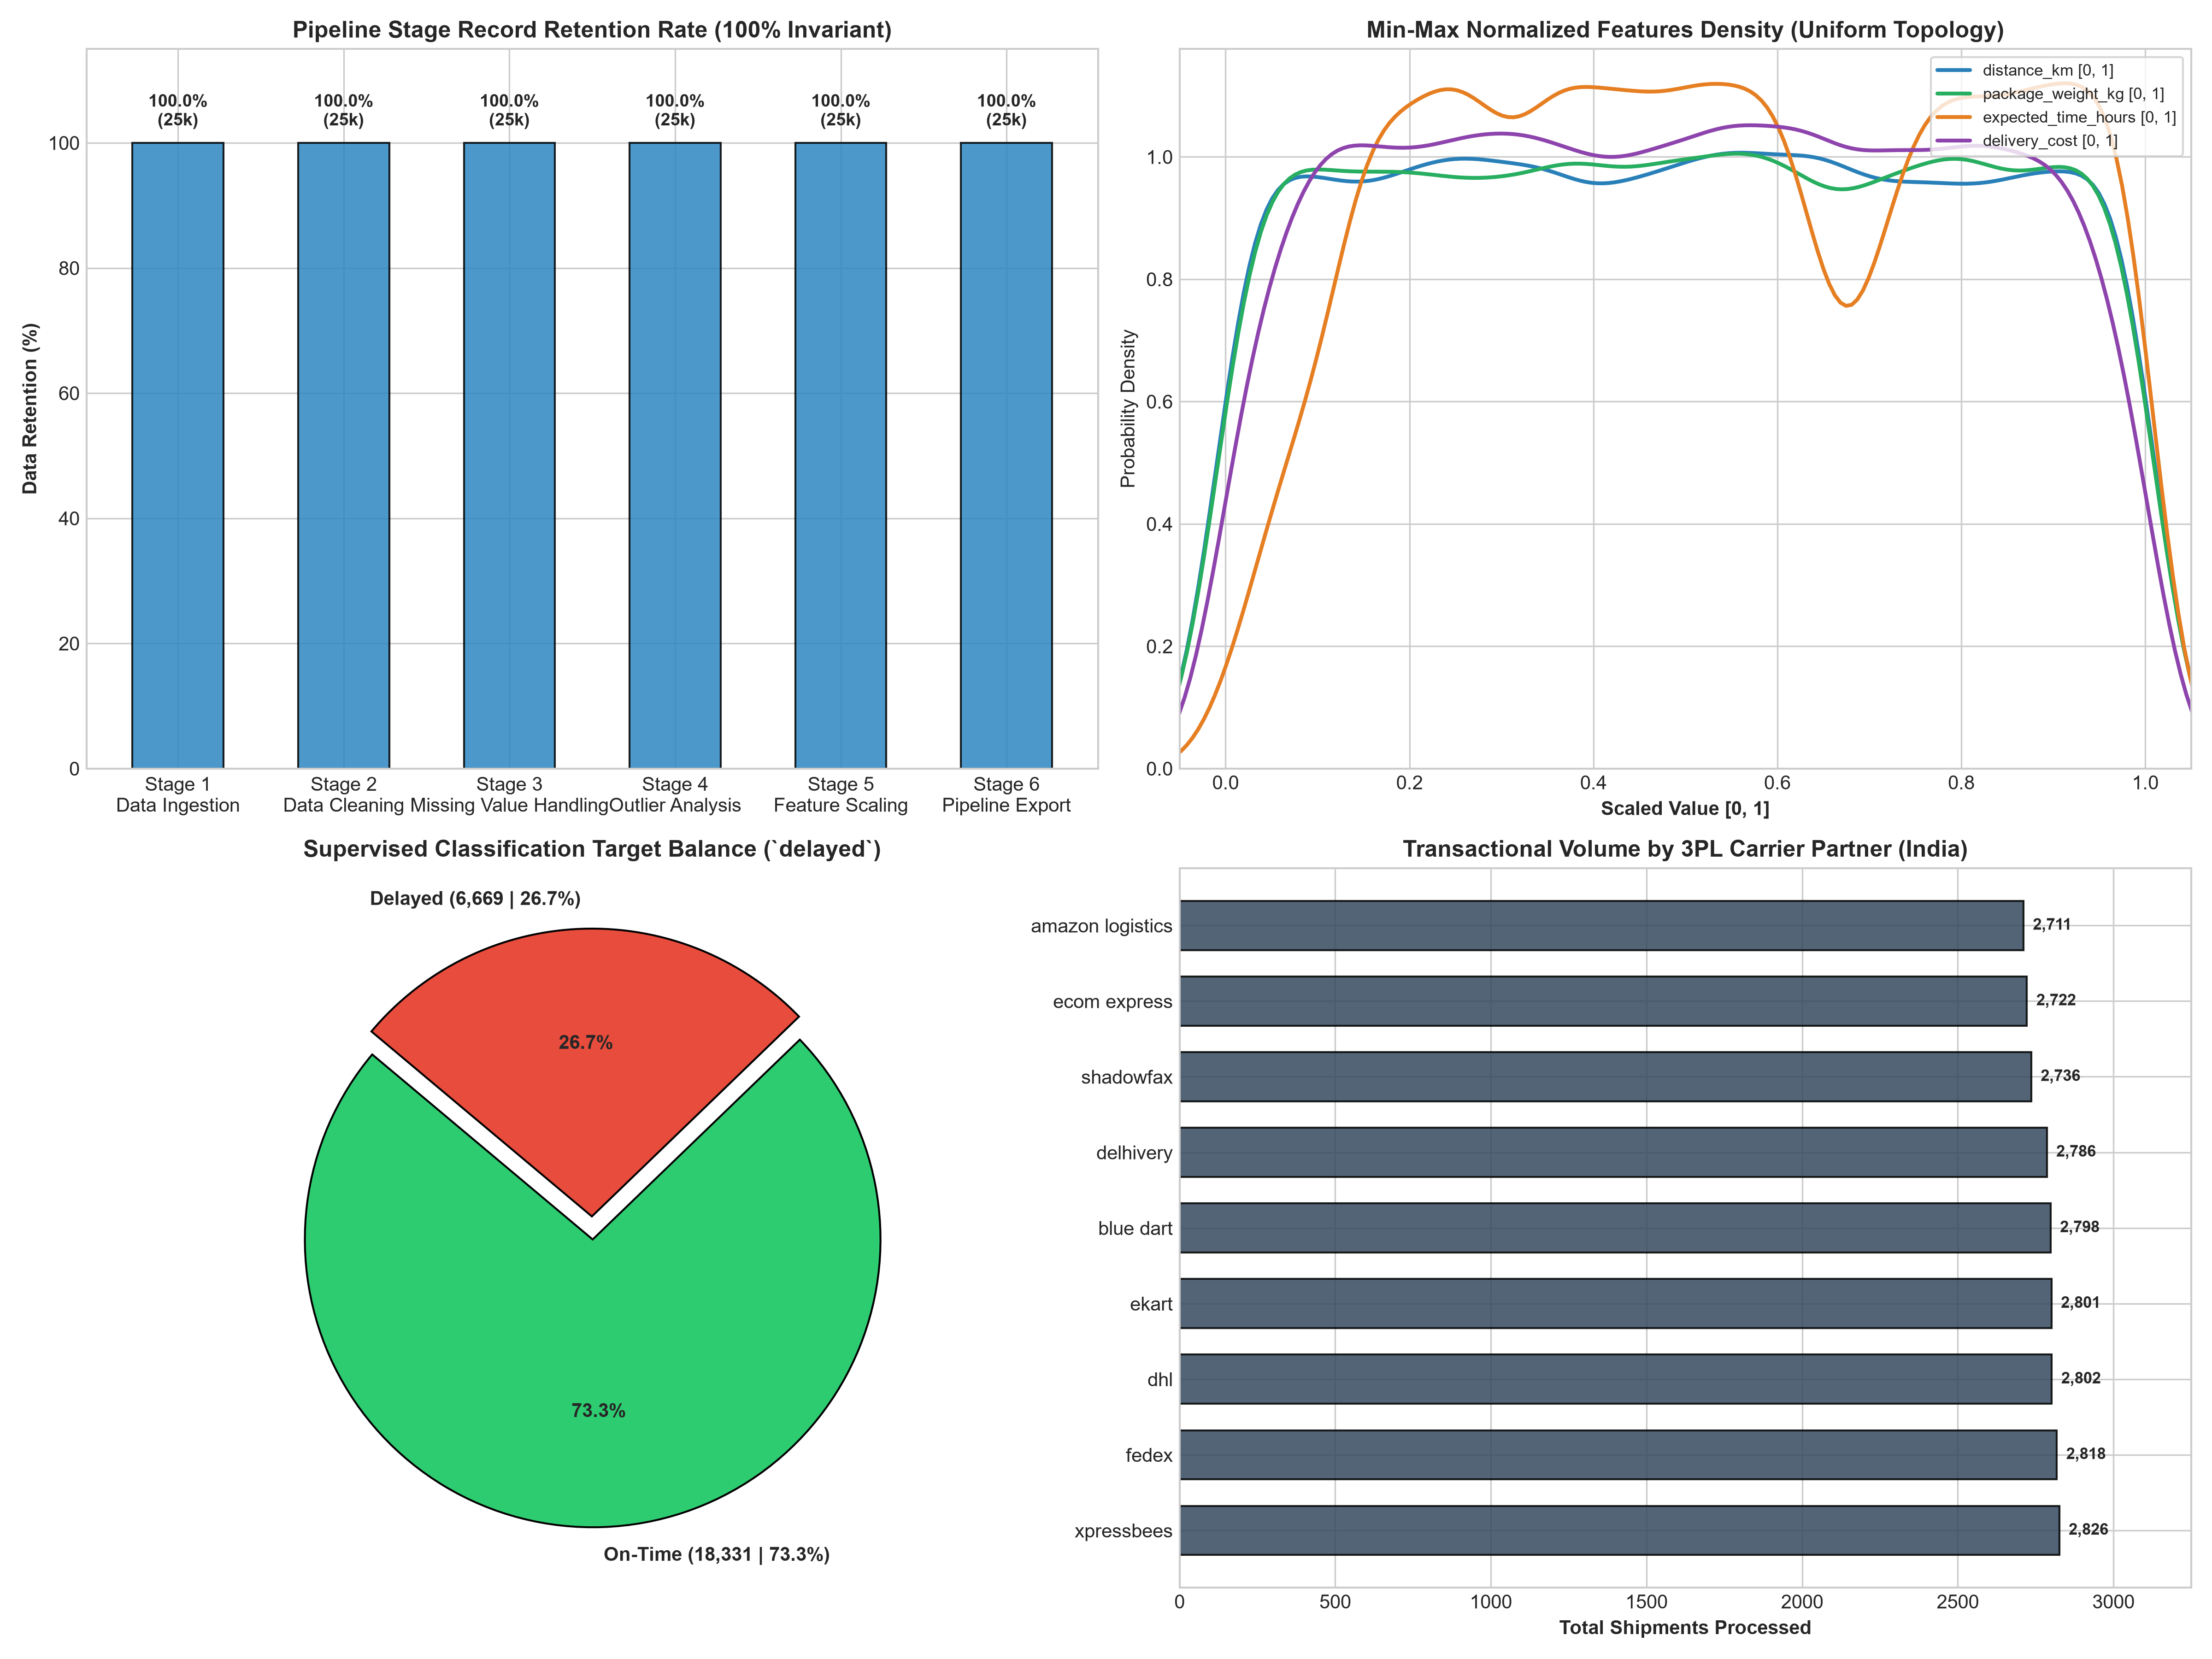

In [40]:
# 7.5 Visual Scorecard Display
summary_img_path = os.path.join(reports_dir, 'charts', 'preprocessing_pipeline_summary.png')
if os.path.exists(summary_img_path):
    from IPython.display import Image
    display(Image(filename=summary_img_path, width=800))
else:
    print("Visual scorecard chart not found at:", summary_img_path)

## 7.6 Step 7 Conclusion & Transition to Week 3
Step 7 marks the successful completion of the **Week 2 Preprocessing Pipeline**:
* **Artifacts Created:** Production datasets serialized in `dataset/processed/`.
* **Zero Data Loss:** 100% of 25,000 transactions and 15 features certified sound.
* **Leakage Quarantine:** `delivery_status` audited and isolated from dispatch features.
* **Preparedness:** The project workspace is fully structured and ready for Week 3: Exploratory Data Analysis, Feature Engineering, and Predictive Modeling.